<h1 align='center'> ELCardio Competition </h1>

### Table of Contents

1. Setup & Imports

2. Data Loading & Parsing

3. Exploratory Data Analysis

4. Dataset Preparation

5. Tokenizer/Sliding Window/BIO Tagging

6. Model Architecture & Training

## Setup & Imports

In [1]:
pip install iterative-stratification

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re
import nltk
import unicodedata
import itertools
import torch
import torch.nn.functional as F

from tqdm import tqdm
from torch import nn
from torch.optim import AdamW
from torch.utils.data import TensorDataset, DataLoader
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import precision_recall_fscore_support, classification_report, f1_score
from tqdm import trange
from nltk import tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.probability import FreqDist
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import CountVectorizer
from dataclasses import dataclass
from sklearn.preprocessing import MultiLabelBinarizer
from typing import List, Dict, Optional, Iterator, Any

In [3]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Data Loading & Parsing

### Dataclasses

In [6]:
@dataclass
class Mention:
    """
    Represents a mention-level annotation within the clinical text.
    
    Attributes:
        start (int): The starting character offset in the document.
        end (int): The ending character offset in the document.
        code (str): The assigned ICD-10 diagnostic code.
        text (str): The actual text span (e.g., "συγκοπτικό επεισόδιο").
    """
    start: int
    end: int
    code: str
    mention: str


@dataclass
class ClinicalDocument:
    """
    Represents a complete clinical document (discharge letter) from the dataset.
    
    Attributes:
        patient_id (Any): Unique identifier for the patient/record.
        text (str): The raw unstructured clinical narrative.
        document_labels (List[List[str]]): A list of lists containing valid ICD-10 codes 
            for the document. The system must predict at least one code from each inner list.
        mentions (Optional[List[Mention]]): A list of mention-level annotations, if available.
    """
    patient_id: Any
    text: str
    document_labels: List[List[str]]
    mentions: Optional[List[Mention]] = None

### Read from jsonl

In [7]:
filepath = "/kaggle/input/datasets/dimitriospakakis/elcardio-dataset/trainELCardioCC2026.jsonl"
all_documents= []
with open(filepath, 'r', encoding='utf-8') as f:
    for line in f:
       json_line = json.loads(line)

       # Load the basic data
       patient_id = json_line['patient_id']
       text = json_line['text']
       document_level_annotations = json_line['document_level_annotations']

       # Load the mentions
       raw_mentions = json_line['mention_level_annotations'] 

       final_mentions = None
      
       # If the mentions list is not empty then we create Mention objects 
       if raw_mentions:
         final_mentions = [Mention(m['start'], m['end'], m['code'], m['mention']) for m in raw_mentions]
       
       all_documents.append(ClinicalDocument(patient_id,text,document_level_annotations,final_mentions))
        
print(len(all_documents))


2500


## Exploratory Data Analysis

### Text-centric EDA

#### Counts and Lengths


Analyzing text counts and lengths provides critical insights into our dataset, such as the **average word length** and the **average number of words per sentence or document**. This analysis is essential for two primary reasons:

1.  **Transformer Constraints:** Most Transformer-based models have a fixed **maximum sequence length** (e.g., 512 tokens). If our text significantly exceeds these limits, information may be lost during truncation, leading to suboptimal model performance.
2.  **Computational Efficiency (Padding vs. Truncation):** We need to evaluate the distribution of text lengths to decide on an optimal cutting point. By identifying outliers, we can avoid excessive **padding** on shorter sequences, which would otherwise lead to unnecessary memory consumption and slower training times.

> **Note:** The final strategy will depend on the variance between the shortest and longest documents in our corpus.

In [8]:

data_for_pd = [{"patient_id":doc.patient_id, "text":doc.text} for doc in all_documents]
text_df = pd.DataFrame(data_for_pd)

#text_df = text_df.set_index("patient_id")

text_df.head()

,patient_id,text
0,2,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...
1,3,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...
2,4,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...
3,11,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...
4,14,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...


In [9]:
# Length per document
text_df['Length'] = text_df['text'].str.len()
text_df.head(10)

,patient_id,text,Length
0,2,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1271
1,3,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1953
2,4,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2023
3,11,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1713
4,14,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2674
5,23,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2378
6,26,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1487
7,32,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2280
8,35,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1963
9,39,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2794


In [10]:
# Number of words in a document
def word_count(document):
    return len(document.split())

text_df['Word_count'] = text_df['text'].apply(word_count)
text_df.head(8)

,patient_id,text,Length,Word_count
0,2,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1271,166
1,3,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1953,275
2,4,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2023,266
3,11,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1713,240
4,14,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2674,396
5,23,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2378,341
6,26,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1487,209
7,32,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2280,293


In [11]:
print(f"The average number of words in documents is: {text_df['Word_count'].mean()}")

The average number of words in documents is: 270.754


In [12]:
# Mean word length
text_df['mean_word_length'] = text_df['text'].map(lambda doc: np.mean([len(word) for word in doc.split()]))
text_df.head(8)

,patient_id,text,Length,Word_count,mean_word_length
0,2,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1271,166,6.620482
1,3,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1953,275,6.080000
2,4,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2023,266,6.586466
3,11,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1713,240,6.116667
4,14,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2674,396,5.739899
5,23,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2378,341,5.953079
6,26,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1487,209,6.081340
7,32,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2280,293,6.767918


In [13]:
# Mean sentence length
text_df['mean_sent_length'] = text_df['text'].map(lambda doc: np.mean([len(sent) for sent in tokenize.sent_tokenize(doc)]))
text_df.head(10)

,patient_id,text,Length,Word_count,mean_word_length,mean_sent_length
0,2,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1271,166,6.620482,157.875000
1,3,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1953,275,6.080000,121.062500
2,4,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2023,266,6.586466,76.692308
3,11,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1713,240,6.116667,284.500000
4,14,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2674,396,5.739899,85.225806
5,23,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2378,341,5.953079,98.000000
6,26,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1487,209,6.081340,105.142857
7,32,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2280,293,6.767918,62.277778
8,35,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,1963,244,7.024590,162.583333
9,39,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...,2794,400,5.970000,198.571429


The 95% of documents have at maximum 451 words.


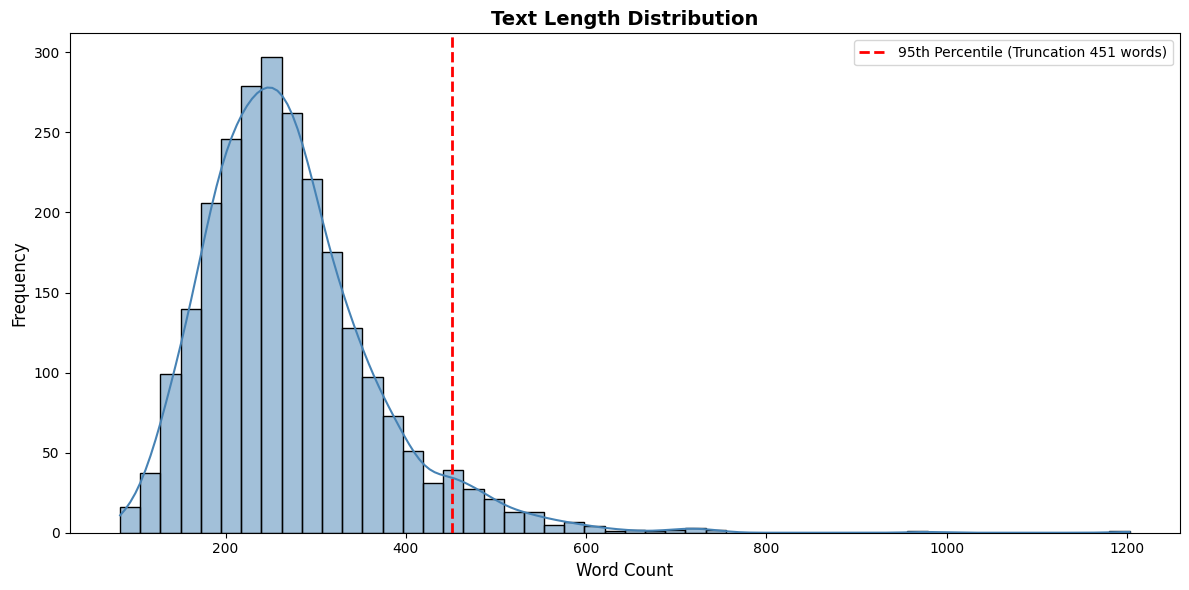

In [14]:
# Word count histogram

max_length_95 = text_df['Word_count'].quantile(0.95)
print(f"The 95% of documents have at maximum {max_length_95:.0f} words.")

plt.figure(figsize=(12, 6))

sns.histplot(data=text_df, x='Word_count', bins=50, kde=True, color='steelblue')

plt.axvline(x=max_length_95, color='red', linestyle='--', linewidth=2, 
            label=f'95th Percentile (Truncation {max_length_95:.0f} words)')

plt.title('Text Length Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Word Count', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

#### Term Frequency Analysis

Beyond simple lengths, we analyze the distribution of terms and their combinations to refine our vocabulary:

* **Term Frequency (TF):** By identifying the most frequent words, we can assess their **informational value**. Recurrent phrases such as *"INFORMATIVE NOTE"* (ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ) often act as domain-specific noise. Since they carry little to no predictive power, we can filter them out to help the model focus on more meaningful features.
* **N-gram Analysis:** We use N-grams (bi-grams, tri-grams) to discover common **word collocations**. This helps us identify sequences of words that consistently appear together. Understanding these patterns allows us to decide whether to treat them as a **single semantic unit (token)**, which can significantly improve the model's ability to capture context.

In [15]:
features = text_df.columns.tolist()[2:]
text_df = text_df.drop(features,axis=1)

text_df.head()


,patient_id,text
0,2,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...
1,3,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...
2,4,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...
3,11,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...
4,14,ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ\nΤο ενημερωτικό σημείωμα ...


In [16]:
# Text cleaner

def remove_accents_from_word(word):

    nfd_form = unicodedata.normalize('NFD', word)
    return "".join([c for c in nfd_form if unicodedata.category(c) != 'Mn'])


def clean_text(document):
    """
    Clean a document by : convert to lowercase, remove punctutations and remove stopwords

    Args:
        document (_type_): the text to be cleaned
    """

    document = document.lower()

    # Greek words have accent mark. We need to remove it from the letters
    document = unicodedata.normalize('NFD',document)
    document = "".join([c for c in document if unicodedata.category(c) != 'Mn'])

    
    document = re.sub(r'[^α-ω0-9\s]', '', document)
    document = " ".join([word for word in document.split() if word not in greek_stopwords])

    return document


greek_stopwords = stopwords.words('greek')
greek_stopwords = [remove_accents_from_word(w) for w in greek_stopwords]
greek_stopwords = set(greek_stopwords)


text_df['text'] = text_df['text'].apply(clean_text)
text_df.head(10)
    

,patient_id,text
0,2,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
1,3,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
2,4,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
3,11,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
4,14,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
5,23,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
6,26,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
7,32,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
8,35,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...
9,39,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...


In [17]:
text_df['text'][0]

'ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετε μαζι σας καθε φορα επισκεπτεστε ιατρο αιτια εισοδου αντικειμενικη εξετεταση ιστορικο αιτια εισοδου αναφερομενο συγκοπτικο επεισοδιο καθιστη θεση χωρις αναφερομενα προδρομα συμπτωματα ταχεια ανανηψη κλινικη εξεταση 13070 σφ 70 12 ευκρινεις ρυθμικοι αψ κφ ατομικο ιστορικο γνωστο οποιο εγινε υπερηχογραφημα καρδιας μυοκαρδιου εξωτερικο ελεγχο ηκγ εισαγωγης 70 ακτινογραφια θωρακος εισαγωγης χωρις παθολογικα ευρηματα πορεια νοσου ασθενης εισηχθη καρδιολογικη κλινικη τεθηκε ρυθμου 24ωρου διενεργηθηκε υπερηχοκαρδιογραφημα καρδιας οποιο ανεδειξε παθολογικα ευρηματα παρεμεινε αιμοδυναμικα σταθερη ασυμπτωματικη εργαστηριακες εξετασεις επισυναπτονται παρακλινικες εξετασεις ηκγ εξοδου χωρις μεταβολη λοιπες εξετασεις καρδιας πορισμα επισυναπτεται ρυθμου πορισμα επισυναπτεται διαγνωση εξοδου επεισοδιο απωλειας συνειδησης διερευνηση γνωστο οδηγιες εξοδο παρατηρησεις τακτικη καρδιολογικη παρακολουθηση επιμελης ληψη φαρμακευτικης αγωγης συσταση μαγνητικη 

In [18]:
# split and create list
def corpus(text):
    return text.split()

text_df['text_lists'] = text_df['text'].apply(corpus)
text_df.head(10)

,patient_id,text,text_lists
0,2,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
1,3,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
2,4,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
3,11,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
4,14,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
5,23,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
6,26,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
7,32,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
8,35,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."
9,39,ενημερωτικο σημειωμα ενημερωτικο σημειωμα εχετ...,"[ενημερωτικο, σημειωμα, ενημερωτικο, σημειωμα,..."


In [19]:
corpus = []
for i in trange(text_df.shape[0], ncols=150, nrows=10, colour='green', smoothing=0.8):
    corpus += text_df['text_lists'][i]
print(len(corpus))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 2500/2500 [00:00<00:00, 125546.39it/s]

474918


In [20]:
mostCommon = Counter(corpus).most_common(20)

print("Our SNR is very low. We can see that the most common words dont provide usefull meaning for the prediction, exept the words ηκγ (electroheartgraph), καρδια (heart) and χωρις (without)")
print(mostCommon)

Our SNR is very low. We can see that the most common words dont provide usefull meaning for the prediction, exept the words ηκγ (electroheartgraph), καρδια (heart) and χωρις (without)
[('11', 8241), ('αγωγη', 6055), ('εξοδου', 5937), ('ασθενης', 5699), ('ηκγ', 4872), ('οδηγιες', 4432), ('εξετασεις', 4197), ('ενημερωτικο', 4170), ('σημειωμα', 4161), ('12', 3732), ('χωρις', 3559), ('1', 3503), ('2', 3352), ('ιστορικο', 3240), ('κλινικη', 3126), ('επισυναπτεται', 2789), ('λογω', 2720), ('καρδιας', 2686), ('πορεια', 2653), ('φαρμακευτικη', 2644)]


In [21]:
words = []
freq = []

for word,count in mostCommon:
    words.append(word)
    freq.append(count)

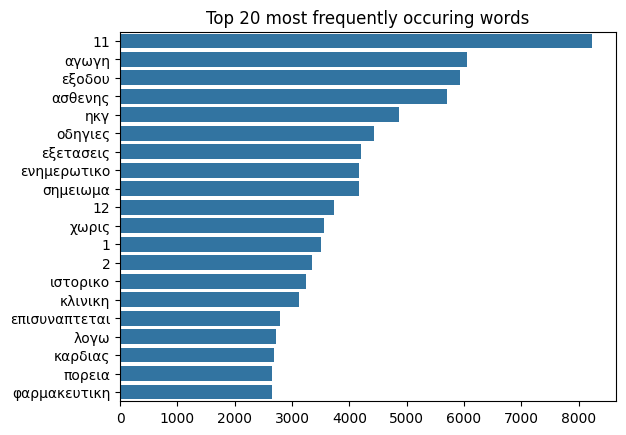

In [22]:
sns.barplot(x=freq, y=words)
plt.title("Top 20 most frequently occuring words")
plt.show()

##### N-gramms (digrams,trigrams)

Digrams

In [23]:
cv = CountVectorizer(ngram_range=(2,2))
bigrams = cv.fit_transform(text_df['text'])

In [24]:
count_values = bigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]

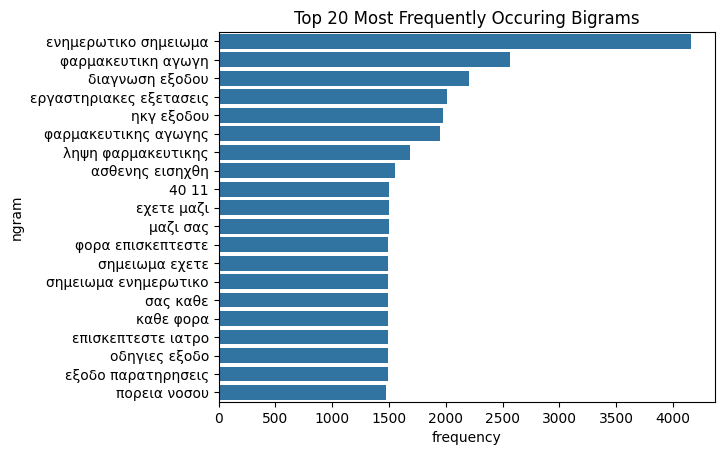

In [25]:
sns.barplot(x=ngram_freq['frequency'][:20], y=ngram_freq['ngram'][:20])
plt.title('Top 20 Most Frequently Occuring Bigrams')
plt.show()

Trigrams

In [26]:
cv1 = CountVectorizer(ngram_range=(3,3))
trigrams = cv1.fit_transform(text_df['text'])
count_values = trigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv1.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]

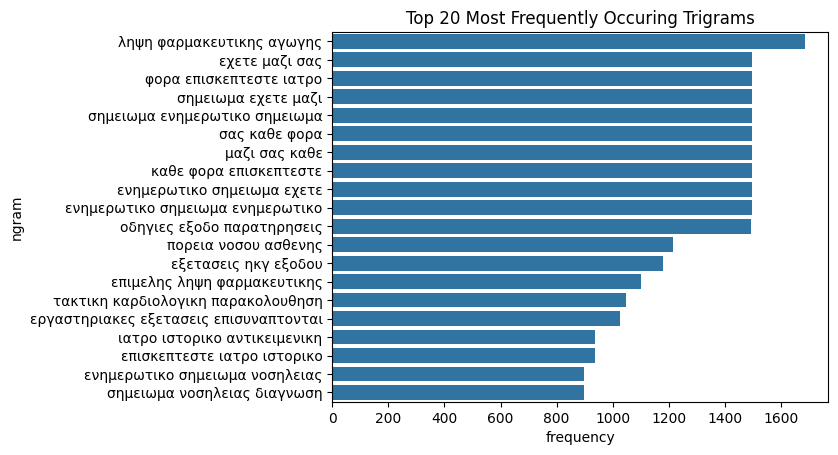

In [27]:
sns.barplot(x=ngram_freq['frequency'][:20], y=ngram_freq['ngram'][:20])
plt.title('Top 20 Most Frequently Occuring Trigrams')
plt.show()

### Label-centric EDA

By analyzing the labels, we can draw important conclusions about the difficulty of the problem, the appropriate loss function, and the evaluation strategy. The analysis will be divided into two parts:

1. **Class imbalance and distribution:** In this part, we examine how frequently each label appears in the dataset. This allows us to understand whether there is an imbalance in label distribution. Based on this, we can appropriately adjust the loss function and select suitable evaluation metrics.

2. **Co-occurrence and cardinality:** Here, we analyze how many labels are assigned to each document on average. This helps us determine the appropriate activation function for the final layer, as well as the threshold to use. Additionally, we explore the relationships between labels by identifying which ones frequently appear together.

#### Class imbalance and distribution

In [28]:
# Count all the difference combinations of labels
code_set = set()
for doc in all_documents:
    doc_labels = doc.document_labels
    for doc_list in doc_labels:
        doc_list = np.sort(doc_list)
        doc_list = "_".join(doc_list)
        code_set.add(doc_list)

print(f"The dataset contains {len(code_set)} different combinations")

The dataset contains 97 different combinations


The code I10_I11 appears 1207 times

The code I25 appears 932 times

The code I48 appears 830 times

The code Z95 appears 829 times

The code Y84 appears 772 times

The code R06 appears 763 times

The code E11 appears 712 times

The code R07 appears 588 times

The code I50 appears 575 times

The code I21 appears 545 times

The code E78 appears 501 times

The code I44 appears 401 times

The code I25_Z95 appears 393 times

The code I20_R07 appears 358 times

The code I21_I22 appears 315 times

The code R00 appears 264 times

The code N18 appears 263 times

The code R53 appears 203 times

The code J81 appears 196 times

The code I45 appears 190 times

The code R60 appears 187 times

The code I49 appears 180 times

The code J44 appears 176 times

The code R55 appears 175 times

The code E00_E03 appears 165 times

The code I64 appears 164 times

The code I20 appears 153 times

The code R42 appears 151 times

The code C00-C97 appears 147 times

The code I35 appears 134 times

The code K92 ap

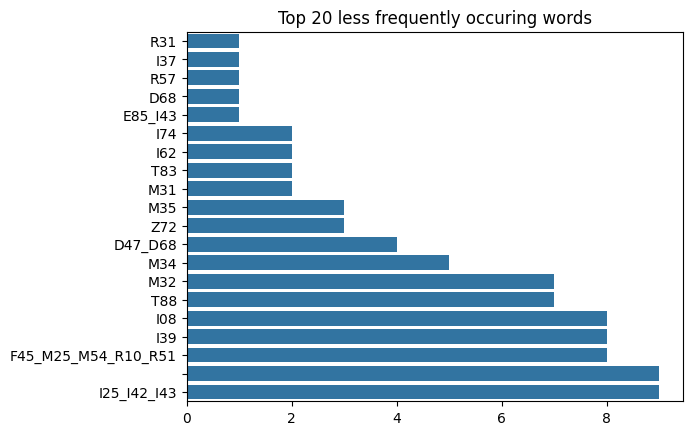

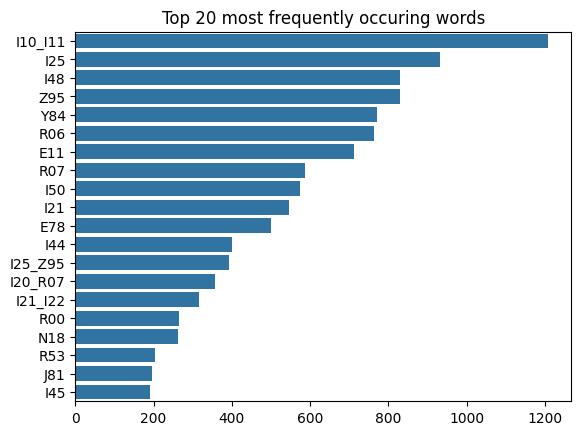

In [29]:
# Count all the difference combinations of labels
code_list = []
for doc in all_documents:
    doc_labels = doc.document_labels
    for doc_list in doc_labels:
        doc_list = np.sort(doc_list)
        doc_list = "_".join(doc_list)
        code_list.append(doc_list)

count_of_labels = Counter(code_list).most_common()
words = []
freq = []
output_string = []
for word,count in count_of_labels:
    words.append(word)
    freq.append(count)
    output_string.append(f"The code {word} appears {count} times")
freq = np.array(freq)
words = np.array(words)
sorted_indexes = np.argsort(freq) 
sorted_freqs = freq[sorted_indexes]
sorted_words = words[sorted_indexes]

for s in output_string:
    print(s + "\n")

sns.barplot(x=sorted_freqs[:20], y=sorted_words[:20])
plt.title("Top 20 less frequently occuring words")
plt.show()

sorted_freqs = sorted_freqs[::-1]
sorted_words = sorted_words[::-1]
sns.barplot(x=sorted_freqs[:20], y=sorted_words[:20])
plt.title("Top 20 most frequently occuring words")
plt.show()

#### Co-occurance and cardinality

Cardinality

The minimum number of codes in a document is: 1
The maximum number of codes in a document is: 16
The average number of codes in a document is: 5.7388


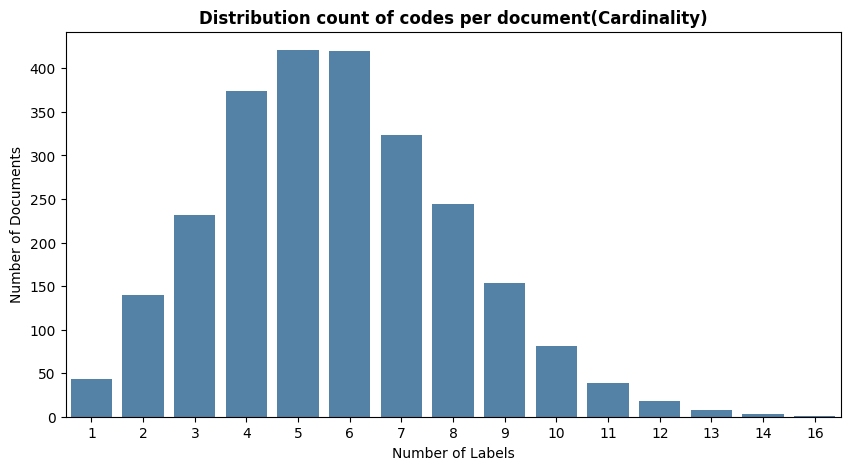

In [30]:
num_of_codes = []
for doc in all_documents:
    doc_labels = doc.document_labels
    num_of_codes.append(len(doc_labels))

print(f"The minimum number of codes in a document is: {np.min(num_of_codes)}")
print(f"The maximum number of codes in a document is: {np.max(num_of_codes)}")
print(f"The average number of codes in a document is: {np.mean(num_of_codes)}")

plt.figure(figsize=(10, 5))
sns.countplot(x=num_of_codes, color='steelblue')
plt.title('Distribution count of codes per document(Cardinality)', fontweight='bold')
plt.xlabel('Number of Labels')
plt.ylabel('Number of Documents')
plt.show()

Co-occurence

In [31]:
pair_counter = Counter()

for doc in all_documents:
    doc_labels = []
    for doc_list in doc.document_labels:
        meta_label = "_".join(np.sort(doc_list))
        doc_labels.append(meta_label)
    
    # Remove the copys
    unique_doc_labels = set(doc_labels)
    
    # Find the combinations per 2
    pairs = itertools.combinations(sorted(unique_doc_labels), 2)
    
    for pair in pairs:
        pair_counter[pair] += 1

print("Top 10 Co-occurring Disease Pairs:")
for pair, count in pair_counter.most_common(20):
    print(f"The combination {pair} appeared {count} times.")

Top 10 Co-occurring Disease Pairs:
The combination ('I25', 'Z95') appeared 540 times.
The combination ('E11', 'I10_I11') appeared 448 times.
The combination ('I10_I11', 'I25') appeared 428 times.
The combination ('I10_I11', 'I48') appeared 424 times.
The combination ('I50', 'R06') appeared 418 times.
The combination ('I25', 'Y84') appeared 400 times.
The combination ('R07', 'Y84') appeared 378 times.
The combination ('I48', 'R06') appeared 372 times.
The combination ('I25_Z95', 'Y84') appeared 365 times.
The combination ('I10_I11', 'R06') appeared 365 times.
The combination ('I10_I11', 'Z95') appeared 361 times.
The combination ('I10_I11', 'Y84') appeared 356 times.
The combination ('E11', 'I25') appeared 340 times.
The combination ('E78', 'I10_I11') appeared 339 times.
The combination ('I21', 'I25') appeared 338 times.
The combination ('I48', 'I50') appeared 312 times.
The combination ('E11', 'R06') appeared 308 times.
The combination ('I21', 'Y84') appeared 307 times.
The combination

### Mention-level EDA

In this analysis, we aim to understand the structure of the mentions, as this will determine how we design the internal labels (BIO tags) for the tokenizer. The analysis will be divided into three parts:

1. **Span Length Distribution:** We examine the length of the phrases (spans). This will help us decide which NER tagging scheme is most appropriate.

2. **Lexical Diversity per Code:** We analyze how much the mentions vary for the same code. This helps us determine whether we need a more advanced model, such as BERT, that can better capture the meaning from the surrounding context.

3. **Density and Overlaps:** First, we examine how many mentions appear in an average document. Then, we check whether there are mentions with the same or overlapping text that correspond to different codes. If this occurs, a token-based NER approach may not be suitable, as it would struggle to correctly assign labels in such cases.


In [32]:
all_mentions = []
for doc in all_documents:
    if doc.mentions != None:
        all_mentions.append(doc.mentions)

print(f"{len(all_mentions)} mention-level annotations found")

1493 mention-level annotations found


In [33]:
count = 0
for document in all_documents:
    ment = document.mentions
    if ment:
        for m in ment:
            st = m.start
            en = m.end
            txt = m.mention
            sliced_text = document.text[st:en]
            if sliced_text != txt:
                count+=1
                print(f"The text in the mention is: {txt} and the text from the document is: {sliced_text}")

print(f"{count} wrong offsets")


The text in the mention is: NSTEMI and the text from the document is: EMI . 
The text in the mention is: προκάρδιο άλγος and the text from the document is: κάρδιο άλγος με
The text in the mention is: Α/Υ and the text from the document is: , κ
The text in the mention is: αγγειοπλαστική and the text from the document is: ειοπλαστική στ
The text in the mention is: αγγειοπλαστικής and the text from the document is: ειοπλαστικής στ
The text in the mention is: NSTEMI and the text from the document is: EMI – 
The text in the mention is: Νόσος 3 αγγείων and the text from the document is: ος 3 αγγείων – 
The text in the mention is: Αγγειοπλαστική and the text from the document is: ειοπλαστική στ
The text in the mention is: πρόσθιο STEMI and the text from the document is: ρόσθιο STEMI 
The text in the mention is: Στεφανιαία Νόσος and the text from the document is: τεφανιαία Νόσος 
The text in the mention is: nSTEMI and the text from the document is: STEMI 
The text in the mention is: Πρόσθιο STE

We can see that we have an data alignment problem

Alignment Algorithm

In [34]:
def fix_mention_offsets(document_text: str, mention: Mention) -> Mention:
    """
    Fix the wrong offsets looking for the rigth string in a window of +/- characters
    """
    # the correct string
    target_text = mention.mention
    
    # Define a search window
    search_start = max(0, mention.start - 15)
    search_end = min(len(document_text), mention.end + 15)
    search_window = document_text[search_start:search_end]
    
    # look up fot the string 
    local_start = search_window.find(target_text)
    
    if local_start != -1:
        # calculate the correct offsets
        new_start = search_start + local_start
        new_end = new_start + len(target_text)
        
        
        return Mention(start=new_start, end=new_end, code=mention.code, mention=target_text)
    else:
        return mention

In [35]:
for document in all_documents:
    doc_mentions = document.mentions
    new_mentions = []
    if doc_mentions:
        for ment in doc_mentions:
          if not ment.end - ment.start < 2:
            new_mentions.append(fix_mention_offsets(document.text,ment))
    document.mentions=new_mentions


all_mentions = []
for doc in all_documents:
    if doc.mentions:
        all_mentions.append(doc.mentions)

print(f"{len(all_mentions)} mention-level annotations found")

1493 mention-level annotations found


In [36]:
count= 0
for document in all_documents:
    ment = document.mentions
    if ment:
        for m in ment:
            new_m = fix_mention_offsets(document.text,m)
            st = new_m.start
            en = new_m.end
            txt = new_m.mention
            sliced_text = document.text[st:en]
            if sliced_text != txt:
                count+=1
print(f"{count} wrong offsets")

0 wrong offsets


#### Span Length Distribution

The minimum number of characters in a mention t is: 2
The maximum number of characters in a mention t is: 145
The average number of characters in a mention t is: 13.920938387042913


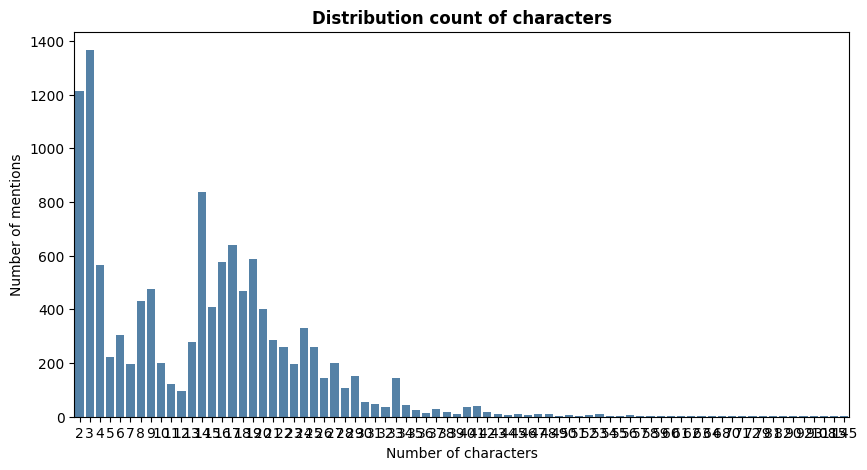

In [37]:
mention_lengths = []
for document in all_documents:
    if document.mentions:
        for doc_ments in document.mentions:
                mention_lengths.append(doc_ments.end - doc_ments.start)


print(f"The minimum number of characters in a mention t is: {np.min(mention_lengths)}")
print(f"The maximum number of characters in a mention t is: {np.max(mention_lengths)}")
print(f"The average number of characters in a mention t is: {np.mean(mention_lengths)}")

plt.figure(figsize=(10, 5))
sns.countplot(x=mention_lengths, color='steelblue')
plt.title('Distribution count of characters', fontweight='bold')
plt.xlabel('Number of characters')
plt.ylabel('Number of mentions')
plt.show()

#### Lexical Diversity per code

In [38]:
codes_mention_diversity = defaultdict(set)

for mentions in all_mentions:
    for mention in mentions:
        code = mention.code
        text = mention.mention.lower().strip()
        codes_mention_diversity[code].add(text)

diversity_counts = []
for code,words_set in codes_mention_diversity.items():
    set_length = len(words_set)
    diversity_counts.append((set_length, code))

diversity_counts.sort(reverse=True)

for count,code in diversity_counts:
    print(f"The code {code} was mentioned with {count} different ways")

The code Z95 was mentioned with 348 different ways
The code R07 was mentioned with 190 different ways
The code I25 was mentioned with 153 different ways
The code I21 was mentioned with 150 different ways
The code I48 was mentioned with 106 different ways
The code I50 was mentioned with 97 different ways
The code I44 was mentioned with 93 different ways
The code I35 was mentioned with 92 different ways
The code I49 was mentioned with 55 different ways
The code R55 was mentioned with 50 different ways
The code R60 was mentioned with 46 different ways
The code R06 was mentioned with 45 different ways
The code R53 was mentioned with 38 different ways
The code I10 was mentioned with 37 different ways
The code C00-C97 was mentioned with 36 different ways
The code N18 was mentioned with 35 different ways
The code Y84 was mentioned with 34 different ways
The code E11 was mentioned with 33 different ways
The code R00 was mentioned with 29 different ways
The code J81 was mentioned with 28 differ

#### Density and Overlap

In [39]:
mentions_count = []
for mentions in all_mentions:
    mentions_count.append(len(mentions))

print(f"The average number of mentions in a mentioned document is: {np.mean(mentions_count)}")
print(f"The maximum number of mentions in a document is: {np.max(mentions_count)}")

The average number of mentions in a mentioned document is: 8.02277294038848
The maximum number of mentions in a document is: 27


In [40]:
total_mentions = 0
overlapping_docs_count = 0

for doc in all_documents:
    if doc.mentions:
        
        total_mentions += len(doc.mentions)
        
        sorted_mentions = sorted(doc.mentions, key=lambda m: m.start)
        
        previous_end = -1
        has_overlap = False
        
        for m in sorted_mentions:
            if m.start < previous_end:
                has_overlap = True
                break 
                
            previous_end = max(previous_end, m.end)
            
        if has_overlap:
            overlapping_docs_count += 1

average_mentions_per_doc = total_mentions / len(all_documents)

print(f"Total Mentions in dataset: {total_mentions}")
print(f"Average mentions in a document (mentioned and not) (Density): {average_mentions_per_doc:.2f}")
print(f"Documents with Overlaps: {overlapping_docs_count}")

Total Mentions in dataset: 11978
Average mentions in a document (mentioned and not) (Density): 4.79
Documents with Overlaps: 3


In [41]:
for doc in all_documents:
    if doc.mentions:
        
        
        sorted_mentions = sorted(doc.mentions, key=lambda m: m.start)
        
        previous_mention = None

        for m in sorted_mentions:
            if previous_mention and m.start < previous_mention.end:
               print("Overlap")
               print(f"First Mention : '{previous_mention.mention}' | Code: {previous_mention.code} | position in document: {previous_mention.start}-{previous_mention.end}")
               print(f"Overlapped mention     : '{m.mention}' | Code: {m.code} | position in document: {m.start}-{m.end}")
               print("-" * 60)
    
            if not previous_mention or m.end > previous_mention.end:
                previous_mention = m

Overlap
First Mention : 'PCI' | Code: Z95 | position in document: 723-726
Overlapped mention     : 'PCI' | Code: Z95 | position in document: 723-726
------------------------------------------------------------
Overlap
First Mention : 'PCI RCA' | Code: Z95 | position in document: 407-414
Overlapped mention     : 'PCI' | Code: Z95 | position in document: 407-410
------------------------------------------------------------
Overlap
First Mention : 'RBBB' | Code: I45 | position in document: 711-715
Overlapped mention     : 'RBBB' | Code: I45 | position in document: 711-715
------------------------------------------------------------


Although we detect overlaps in the mention annotations, this does not pose a serious problem, since the overlapping mentions correspond to the same codes.

This means that we can keep the longest span in each case. By doing so, we both resolve the overlap issue and retain all the information, without any loss.

## Results of EDA

#### Text-Centric EDA

95% of the documents contain up to ~450 words. Additionally, the texts include a significant amount of noise (e.g., “ΕΝΗΜΕΡΩΤΙΚΟ ΣΗΜΕΙΩΜΑ”) and exhibit a low signal-to-noise ratio.

We do not remove stopwords. Modern models (such as Transformers) rely on grammatical structure to better understand the context. In the tokenizer, we set the maximum sequence length (max_len) to around 512 tokens.
This covers more than 95% of our documents without wasting GPU memory (VRAM) on excessive padding.

#### Label-centric EDA

We have 97 unique conditions (meta-labels) with a highly imbalanced distribution (ranging from 1207 occurrences down to just 1). On average, each patient has around 6 conditions, with a maximum of up to 16.

Architecture: The final layer (classification head) of the model will consist of 97 neurons.

Activation & Loss: We will use a Sigmoid activation function (instead of Softmax), along with a loss function that can handle class imbalance, such as Focal Loss or BCEWithLogitsLoss with class weights.

Evaluation: The model will be evaluated strictly using Macro F1-score, ensuring that rare conditions are given equal importance.

#### Mention-level EDA

We identified offset misalignment, redundant overlaps, and extremely high lexical diversity (e.g., 348 different ways to express the same condition).

Data: We corrected the offsets and removed the overlaps. The dataset is now flat and clean from a clinical perspective.
Model: The high lexical diversity confirms the need for a model like BERT (contextual embeddings) rather than simple dictionary-based approaches.
Tagging: We will use the BIO format (Begin, Inside, Outside). Since the dataset is sparse (most tokens belong to class O), we will assign a lower weight to the O class during NER training.

#### Remove overlaps

In [42]:
overlaps_removed = 0

for doc in all_documents:
    if not doc.mentions:
        continue
        
    # Sort the mentions in a way that the longest mention is at the 1st position
    sorted_mentions = sorted(doc.mentions, key=lambda m: (m.start, -m.end))
    
    clean_mentions = []
    
    for m in sorted_mentions:
        if not clean_mentions:
            clean_mentions.append(m)
        else:
            last_mention = clean_mentions[-1]
            
            if m.start < last_mention.end:
                overlaps_removed += 1
                continue
            else:
                clean_mentions.append(m)
                
    doc.mentions = clean_mentions

print(f"{overlaps_removed} redundant/overlapping mentions were deleted.")

3 redundant/overlapping mentions were deleted.


#### Data after EDA

1. The number of documents is the same.

2. The number of mentioned document is the same.

3. The number of mentions is reduced by 3 mentions.

4. The numbers in the mentions are changed to correct the offset.

## Dataset Split

We will split the dataset to 90% train and 5% validation and 5% test. We will handle the codes that are rare. If a code has only 1 document, it will be in the training set. If there are more than 2 documents then there will be an uniform distribution in both test, train and validation sets

We can not convert the y_labels list to numpy array or tensor because every document has a different number of codes, but the 2nd dimension must be the same for all the samples. So, to improve the performance of the training and to solve this issue, we will convert the codes with multi-Hot Encoding. Each label list will be converted to a list where the true codes will be converted to 1 and the false to 0.

In [43]:
X_texts = []
y_labels_raw = []
y_labels = []
for doc in all_documents:
    X_texts.append(doc.text)
    
    current_labels = []
    for label_list in doc.document_labels:
        for label in label_list:
            current_labels.append(label)
    y_labels.append(current_labels.copy())
    # Add extra flag to stratify the set using the labels and the mentions
    if doc.mentions and len(doc.mentions) > 0:
        current_labels.append("HAS_MENTION")
        
    y_labels_raw.append(current_labels)

X_texts = np.array(X_texts)

# Binarization
mlb = MultiLabelBinarizer()
y_encoded = mlb.fit_transform(y_labels_raw)

mlb2 = MultiLabelBinarizer()
y_labels = mlb2.fit_transform(y_labels)

# 3. Stratified Split (90% Train, 5% Val, 5% Test)
X_indices = np.arange(len(all_documents))

# --- Split: 90% Train / 10% Temp ---
msss_1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, temp_idx = next(msss_1.split(X_indices, y_encoded))

# --- Split: 5% Val / 5% Test ---
msss_2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_local_idx, test_local_idx = next(msss_2.split(temp_idx, y_encoded[temp_idx]))

val_idx = temp_idx[val_local_idx]
test_idx = temp_idx[test_local_idx]

train_docs = [all_documents[i] for i in train_idx]
val_docs = [all_documents[i] for i in val_idx]
test_docs = [all_documents[i] for i in test_idx]

y_train = y_labels[train_idx]
y_val = y_labels[val_idx]
y_test = y_labels[test_idx]

string_labels = mlb2.classes_
# Εκτυπώσεις
print(f"y_labels shape: {y_labels.shape}")
print(f"Example y_labels[0]: {y_labels[0]}")
print(f"Labels document 0: {string_labels[y_labels[0] == 1]}\n")

print(f"Total documents: {len(all_documents)}")
print("-" * 30)
print(f"Train Set:      {len(train_docs)}")
print(f"Validation Set: {len(val_docs)}")
print(f"Test Set:       {len(test_docs)}")

y_labels shape: (2500, 110)
Example y_labels[0]: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]
Labels document 0: ['I10' 'I11' 'I44' 'R55' 'Z95']

Total documents: 2500
------------------------------
Train Set:      2238
Validation Set: 134
Test Set:       128


## Curriculum learning split

We will split the training in 2 phases. Phase 1 -> Only mentioned documents, where every chunk will have the code from the mention annotation. Phase 2-> Not mentioned Documents, where we will use multiple instance learning using maxpool

In [44]:
train_docs_phase1 = []
y_train_phase1 = []

train_docs_phase2 = []
y_train_phase2 = []

# Only the training set
for doc, y in zip(train_docs, y_train):
    if doc.mentions and len(doc.mentions)>0:
        # Strong supervision
        train_docs_phase1.append(doc)
        y_train_phase1.append(y)
    else:
        # Weak Supervision
        train_docs_phase2.append(doc)
        y_train_phase2.append(y)

y_train_phase1 = np.array(y_train_phase1)
y_train_phase2 = np.array(y_train_phase2)

print("\n=== CURRICULUM LEARNING SPLIT ===")
print(f"Phase 1 Train Docs (With Mentions): {len(train_docs_phase1)}")
print(f"Phase 2 Train Docs (No Mentions):   {len(train_docs_phase2)}")


=== CURRICULUM LEARNING SPLIT ===
Phase 1 Train Docs (With Mentions): 1331
Phase 2 Train Docs (No Mentions):   907


In [45]:
train_counts = y_train.sum(axis=0)
val_counts = y_val.sum(axis=0)
test_counts = y_test.sum(axis=0)
total_counts = train_counts + val_counts + test_counts

print("--- Check the samples with Frequency = 1 (we must see that the train set contains these samples) ---")
for i, class_name in enumerate(string_labels):
    if total_counts[i] == 1:
        print(f"Code: {class_name:<10} | Train: {train_counts[i]} | Validation: {val_counts[i]}")

print("\n---Check the frequent samples (we must see approximantly 90-5-5 percent) ---")
printed_frequent = 0
for i, class_name in enumerate(string_labels):
    if total_counts[i] > 50 and printed_frequent < 5:
        train_pct = (train_counts[i] / total_counts[i]) * 100
        val_pct = (val_counts[i] / total_counts[i]) * 100
        test_pct = (test_counts[i] / total_counts[i]) * 100
        print(f"Code: {class_name:<10} | Total: {total_counts[i]:<4} | Train: {train_counts[i]} ({train_pct:.1f}%) | Val: {val_counts[i]} ({val_pct:.1f}% | Train: {test_counts[i]} ({test_pct:.1f}%))")
        printed_frequent += 1

--- Check the samples with Frequency = 1 (we must see that the train set contains these samples) ---
Code: E85        | Train: 1 | Validation: 0
Code: I37        | Train: 1 | Validation: 0
Code: R31        | Train: 1 | Validation: 0
Code: R57        | Train: 1 | Validation: 0

---Check the frequent samples (we must see approximantly 90-5-5 percent) ---
Code: C00-C97    | Total: 147  | Train: 132 (89.8%) | Val: 8 (5.4% | Train: 7 (4.8%))
Code: D50-D64    | Total: 79   | Train: 71 (89.9%) | Val: 4 (5.1% | Train: 4 (5.1%))
Code: E00        | Total: 165  | Train: 149 (90.3%) | Val: 8 (4.8% | Train: 8 (4.8%))
Code: E03        | Total: 165  | Train: 149 (90.3%) | Val: 8 (4.8% | Train: 8 (4.8%))
Code: E11        | Total: 712  | Train: 641 (90.0%) | Val: 37 (5.2% | Train: 34 (4.8%))


## END of EDA & Data Preperation

## TRIALS AND EXPERIMENT

### Tokenization

In [46]:
tokenizer = AutoTokenizer.from_pretrained('nlpaueb/bert-base-greek-uncased-v1', do_lower_case = True, strip_accents = True)

config.json:   0%|          | 0.00/459 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [47]:
text = "Λόγω αυξημένης τιμής D-dimers έγινε CTPA που ανέδειξε πνευμονική εμβολή άμφω. Έγινε εισαγωγή στη Στεφανιαία Μονάδα όπου τέθηκε σε αντιπηκτική αγωγή παραμένοντας ασυμπτωματικός και αιμοδυναμικά σταθερός."
print(text)
# 1. Ας δούμε πώς σπάει τις λέξεις (Τα sub-words)
tokens = tokenizer.tokenize(text)
print("Sub-words:", tokens)

# 2. Ας δούμε τους αριθμούς που θα πάνε στο Νευρωνικό Δίκτυο (input_ids)
encoded = tokenizer(text)
print("\nΛεξικό (Tensors):")
print("Input IDs:", encoded["input_ids"])
print("Attention Mask:", encoded["attention_mask"])

Λόγω αυξημένης τιμής D-dimers έγινε CTPA που ανέδειξε πνευμονική εμβολή άμφω. Έγινε εισαγωγή στη Στεφανιαία Μονάδα όπου τέθηκε σε αντιπηκτική αγωγή παραμένοντας ασυμπτωματικός και αιμοδυναμικά σταθερός.
Sub-words: ['λογω', 'αυξημενη', '##ς', 'τιμης', 'd', '-', 'dim', '##ers', 'εγινε', 'c', '##tp', '##a', 'που', 'ανεδειξε', 'πνευμονικη', 'εμ', '##βολη', 'αμ', '##φω', '.', 'εγινε', 'εισαγωγη', 'στη', 'στεφανιαια', 'μοναδα', 'οπου', 'τεθηκε', 'σε', 'αντιπηκτικ', '##η', 'αγωγη', 'παραμενοντας', 'ασ', '##υμ', '##πτω', '##ματικο', '##ς', 'και', 'αιμο', '##δυνα', '##μικα', 'σταθερο', '##ς', '.']

Λεξικό (Tensors):
Input IDs: [101, 508, 4556, 278, 3641, 159, 120, 19868, 1810, 579, 158, 13186, 182, 354, 15515, 31060, 1987, 8202, 2361, 5596, 121, 579, 1796, 372, 27844, 2089, 439, 9652, 356, 34247, 267, 3410, 26885, 4291, 3573, 6897, 16907, 278, 344, 9127, 6535, 9623, 3136, 278, 121, 102]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

BERT accepts 512 tokens, so we must see how many documents have more than 512 tokens

In [48]:
tokens_len = []
count = 0
for doc in all_documents:
    tokens = tokenizer.tokenize(doc.text)
    tokens_len.append(len(tokens))
    if len(tokens) > 512:
        count+=1

print(f"{count} documents from {len(all_documents)} have more than 512 tokens")
print("The maximum length of tokens is: ",np.max(tokens_len))


1166 documents from 2500 have more than 512 tokens
The maximum length of tokens is:  2165


### BIO Tagging

#### Trial

In [49]:
text = "Ο ασθενής έχει αρρυθμία."
encoded_with_offsets = tokenizer(text, return_offsets_mapping=True)
print("Tokens:", tokenizer.convert_ids_to_tokens(encoded_with_offsets['input_ids']))
print(f"Offsets:", encoded_with_offsets['offset_mapping'])
print("Input IDs:", encoded_with_offsets["input_ids"])


Tokens: ['[CLS]', 'ο', 'ασθενης', 'εχει', 'αρρυθμι', '##α', '.', '[SEP]']
Offsets: [(0, 0), (0, 1), (2, 9), (10, 14), (15, 22), (22, 23), (23, 24), (0, 0)]
Input IDs: [101, 247, 6238, 377, 30347, 261, 121, 102]


In [50]:
a_doc = all_documents[0]
a_doc_text = a_doc.text
encoded = tokenizer(a_doc_text, return_offsets_mapping=True)
tokens = tokenizer.convert_ids_to_tokens(encoded['input_ids'])
tokens = np.array(tokens)
labels = ['O' for _ in range(len(encoded['input_ids']))]
for i, (start,end) in enumerate(encoded['offset_mapping']):
    if start!=end:
        if a_doc.mentions:
            for mention in a_doc.mentions:
                if start >= mention.start and end <= mention.end:
                    if i == 0 or labels[i-1] not in [f"B-{mention.code}", f"I-{mention.code}"]:
                        labels[i] = f"B-{mention.code}"
                    else:
                        labels[i] = f"I-{mention.code}"

labels = np.array(labels)

tok = []
lab = []
for i,label in enumerate(labels):
    if label !='O':
        tok.append(tokens[i])
        lab.append(label)
print(tok)
print(lab)


[np.str_('συγκ'), np.str_('##οπ'), np.str_('##τικο'), np.str_('επεισοδιο'), np.str_('a'), np.str_('##y'), np.str_('l'), np.str_('##bb'), np.str_('##b'), np.str_('l'), np.str_('##bb'), np.str_('##b'), np.str_('hol'), np.str_('##ter'), np.str_('ρυθμου'), np.str_('24'), np.str_('##ωρου'), np.str_('hol'), np.str_('##ter'), np.str_('ρυθμου'), np.str_('επεισοδιο'), np.str_('απωλειας'), np.str_('συνειδησης'), np.str_('l'), np.str_('##bb'), np.str_('##b'), np.str_('a'), np.str_('##y'), np.str_('αυ')]
[np.str_('B-R55'), np.str_('I-R55'), np.str_('I-R55'), np.str_('I-R55'), np.str_('B-I10'), np.str_('I-I10'), np.str_('B-I44'), np.str_('I-I44'), np.str_('I-I44'), np.str_('B-I44'), np.str_('I-I44'), np.str_('I-I44'), np.str_('B-Z95'), np.str_('I-Z95'), np.str_('I-Z95'), np.str_('I-Z95'), np.str_('I-Z95'), np.str_('B-Z95'), np.str_('I-Z95'), np.str_('I-Z95'), np.str_('B-R55'), np.str_('I-R55'), np.str_('I-R55'), np.str_('B-I44'), np.str_('I-I44'), np.str_('I-I44'), np.str_('B-I10'), np.str_('I-I10'

Slicing Window

In [51]:
max_len = 512
overlap = 128
stride = max_len - overlap  # Το βήμα μας (384)
total_tokens = 2165

# Υπολογισμός όλων των chunks με ασφάλεια
indexes = [(i, min(i + max_len, total_tokens)) for i in range(0, total_tokens, stride)]
print(indexes)

[(0, 512), (384, 896), (768, 1280), (1152, 1664), (1536, 2048), (1920, 2165)]


#### Create Lists using the slicing window method, using stride and max_length

In [52]:
tokens_set = []
input_ids_set = []
offsets_set = []
mapping_set = []
attention_mask_set = []
for doc_index,doc in enumerate(all_documents):
    doc_text = doc.text
    encoded = tokenizer(doc_text, return_offsets_mapping=True, return_overflowing_tokens=True, stride=128, max_length=512, padding='max_length', truncation=True)
    attention_mask = encoded["attention_mask"]
    input_ids = encoded['input_ids']
    offsets = encoded['offset_mapping']
    for i in range(len(input_ids)):
        tokens_set.append(tokenizer.convert_ids_to_tokens(input_ids[i]))
        attention_mask_set.append(attention_mask[i])
        offsets_set.append(offsets[i])
        input_ids_set.append(input_ids[i])
        mapping_set.append(doc_index)


In [53]:
print(f"Tokens: {tokens_set[0]}")
print(f"IDs: {input_ids_set[0]}")
print(f"Offsets: {offsets_set[0]}")
print(f"From document: {mapping_set[0]}")

Tokens: ['[CLS]', 'ενημερωτικο', 'σημειωμα', 'το', 'ενημερωτικο', 'σημειωμα', 'να', 'το', 'εχετε', 'μαζι', 'σας', 'καθε', 'φορα', 'που', 'θα', 'επισκεπτεστε', 'τον', 'ιατρο', 'αιτια', 'εισοδου', '–', 'αντικειμενικη', 'εξε', '##τε', '##ταση', '-', 'ιστορικο', 'αιτια', 'εισοδου', ':', 'αναφερομενο', 'συγκ', '##οπ', '##τικο', 'επεισοδιο', 'σε', 'καθ', '##ιστη', 'θεση', ',', 'χωρις', 'αναφερομενα', 'προ', '##δρομ', '##α', 'συμπτωματα', ',', 'με', 'ταχεια', 'ανα', '##ν', '##η', '##ψη', 'κλινικη', 'εξεταση', ':', 'απ', ':', '130', '/', '70', 'mm', '##h', '##g', ',', 'σφ', ':', '70', '/', 'min', ',', 's', '##1', '-', 's', '##2', ':', 'ευκ', '##ριν', '##εις', ',', 'ρυ', '##θμ', '##ικοι', 'α', '/', 'ψ', ':', 'κ', '##φ', 'ατομικο', 'ιστορικο', ':', 'a', '##y', ',', 'γνωστο', 'l', '##bb', '##b', '(', 'για', 'το', 'οποιο', 'εγινε', 'υπερηχογραφημα', 'καρδιας', 'και', 'spec', '##t', 'μυοκαρδιο', '##υ', 'σε', 'εξωτερικο', 'ελεγχο', ')', 'η', '##κ', '##γ', 'εισαγωγης', ':', 's', '##r', ',', 'l', '##b

#### Create BIO tagging list

In [54]:
bio_labels_set = []

for i in range(len(input_ids_set)):

    # Initialize the tags
    labels = ['O'] * len(input_ids_set[i])

    for j, (start,end) in enumerate(offsets_set[i]):

        # Check if special token
        if start==end==0:
            labels[j] = -100
            continue

        # Check if is in mention
        if all_documents[mapping_set[i]].mentions:
             for mention in all_documents[mapping_set[i]].mentions:
                  if start >= mention.start and end <= mention.end:
                       if j == 0 or labels[j-1] not in [f"B-{mention.code}", f"I-{mention.code}"]:
                            labels[j] = f"B-{mention.code}"
                       else:
                            labels[j] = f"I-{mention.code}"
                       break
                  
    bio_labels_set.append(labels)



## Tokenization/ Sliding Window/ BIO Tagging

We will use the greekBERT tokenizer to tokenize the text. In the previous section we saw that a lot of documents have more than 512 tokens. So we will use a sliding window technique to convert the big documents to chunks. After we will tag the tokens with the mentions we have using the BIO tagging technique. The fact that we will create chunks from the documents creates a problem with the labels. There is not a single way to solve this , so we will experiment with this

In [55]:
def prepare_features(docs, y_labels, tokenizer, string_labels):
    all_input_ids = []
    all_attention_masks = []
    all_ner_labels = []     #  BIO tags
    all_class_labels = []   # multi-hot encoding
    all_patient_ids = []

    for doc_idx, doc in enumerate(docs):
        doc_y = y_labels[doc_idx]
        
        # 2. Tokenization & Sliding Window
        encoded = tokenizer(
            doc.text,
            padding='max_length',
            truncation=True,
            max_length=512,
            stride=64,
            return_overflowing_tokens=True,
            return_offsets_mapping=True
        )
        
        # for every chunk in the document
        for chunk_idx in range(len(encoded['input_ids'])):
            chunk_input_ids = encoded['input_ids'][chunk_idx]
            chunk_mask = encoded['attention_mask'][chunk_idx]
            chunk_offsets = encoded['offset_mapping'][chunk_idx]
            
            
            # Initialize BIO tags
            chunk_ner_tags = ['O'] * 512
            
            # Initialize the labels 
            chunk_class_label = np.zeros(110, dtype=int)
            
            # If the document has mention annotation for the labels
            if doc.mentions and len(doc.mentions) > 0:
                for i, (start, end) in enumerate(chunk_offsets):
                    
                    # Check if special token
                    if start==end==0:
                        chunk_ner_tags[i] = -100
                        continue
                    
                    for mention in doc.mentions:
                        if start >= mention.start and end <= mention.end:
                            if i == 0 or chunk_ner_tags[i-1] not in [f"B-{mention.code}", f"I-{mention.code}"]:
                                chunk_ner_tags[i] = f"B-{mention.code}"
                            else:
                                chunk_ner_tags[i] = f"I-{mention.code}"
                            index = np.where(string_labels == mention.code)
                            chunk_class_label[index] = 1
                            break
                    pass 
            else:
                # If the document does not have mentions then we set all tags to -100 so pytorch will ignore them
                chunk_ner_tags = [-100] * 512
                
                chunk_class_label = doc_y
                pass
                
            # Save the chunks results to the lists
            all_patient_ids.append(doc.patient_id)
            all_input_ids.append(chunk_input_ids)
            all_attention_masks.append(chunk_mask)
            all_ner_labels.append(chunk_ner_tags)
            all_class_labels.append(chunk_class_label)

    return all_input_ids, all_attention_masks, all_ner_labels, all_class_labels, all_patient_ids
    

#### Testing prepare features function

In [56]:
# Select documents and binarized labels (110 θέσεων)
test_indices = [30, 80, 2000, 2310]
sample_docs = [all_documents[i] for i in test_indices]
sample_y = y_labels[test_indices] 

test_input_ids, test_masks, test_ner, test_class,_ = prepare_features(
    docs=sample_docs, 
    y_labels=sample_y, 
    tokenizer=tokenizer, 
    string_labels=string_labels  
)

print("="*50)
print("SANITY CHECK ".center(50, "="))
print("="*50)

chunk_counter = 0

for doc_i, doc in enumerate(sample_docs):
    print(f"\n[{'WITH MENTIONS' if doc.mentions else 'WITHOUT MENTIONS'}] Document Index: {test_indices[doc_i]}")
    print(f"Initial document labels: {doc.document_labels}")
    print("-" * 40)
    
    temp_enc = tokenizer(doc.text, max_length=512, stride=64, truncation=True, return_overflowing_tokens=True)
    num_chunks = len(temp_enc['input_ids'])
    
    for c in range(num_chunks):
        print(f"  -> Chunk {chunk_counter + 1} (From document {test_indices[doc_i]}):")
        
        # Document Classification Label 
        active_classes_idx = np.where(test_class[chunk_counter] == 1)[0]
        active_classes_str = mlb2.classes_[active_classes_idx]
        print(f"     Inherited Class Label: {active_classes_str}")
        
        # BIO Tags
        chunk_tags = test_ner[chunk_counter]
        
        if doc.mentions:
            found_mentions = False
            for token_idx, tag in enumerate(chunk_tags):
                if tag != 'O' and tag != -100:
                    word = tokenizer.decode([test_input_ids[chunk_counter][token_idx]])
                    print(f"     [NER] Found {tag} for thw word: '{word}'")
                    found_mentions = True
            
            if not found_mentions:
                print("     [NER] No mentions in the chunk. All tags are 'O' or -100.")
        else:
            unique_tags = set(chunk_tags)
            print(f"     [NER] BIO tags in this chunk are: {unique_tags} (We wait {-100})")
            
        print("  " + "."*38)
        chunk_counter += 1

==================SANITY CHECK ===================

[WITH MENTIONS] Document Index: 30
Initial document labels: [['I20'], ['R07'], ['I25'], ['Y84']]
----------------------------------------
  -> Chunk 1 (From document 30):
     Inherited Class Label: ['I20' 'I25' 'R07' 'Y84']
     [NER] Found B-R07 for thw word: 'προ'
     [NER] Found I-R07 for thw word: '##καρδι'
     [NER] Found I-R07 for thw word: '##ο'
     [NER] Found I-R07 for thw word: 'αλ'
     [NER] Found I-R07 for thw word: '##γος'
     [NER] Found B-I25 for thw word: 'στεφανιαια'
     [NER] Found I-I25 for thw word: 'νοσος'
     [NER] Found B-Y84 for thw word: 'στεφανι'
     [NER] Found I-Y84 for thw word: '##ο'
     [NER] Found I-Y84 for thw word: '##γραφικο'
     [NER] Found I-Y84 for thw word: '##ς'
     [NER] Found I-Y84 for thw word: 'ελεγχος'
     [NER] Found B-I20 for thw word: 'αστα'
     [NER] Found I-I20 for thw word: '##θη'
     [NER] Found I-I20 for thw word: '##ς'
     [NER] Found I-I20 for thw word: 'στη'
     

## Convert the data to tensors

Let's say that this section is where analysis and experiments stop and starts the 'real' nlp task. To summarize our previous work:

1. We have 3 sets. Training/Validation/Test.

2. We have 4 lists: input_ids, attention_masks, ner_labels, class_labels, for each set.

3. We used a sliding window to create tokens_sets of max 512 tokens and to keep all information, we didnt truncate but we splitted the documents to chunks

4. The chunks of documents with mentions will have the labels from the mentions for each chunk

5. The chunks of documents without mentions will inherit the labels from the global document (it is possible that this way add false information).

#### Convert BIO Tags to numbers

Create tag to id dictionary

In [57]:
tag2id_dict = {}
tag2id_dict['O'] = 0
counter = 0
for code in string_labels:
    counter+=1
    tag2id_dict['B-' + code] = counter
    counter+=1
    tag2id_dict['I-' + code] = counter


In [58]:
def convert_tag2id(ner_labels,tag2id_dict):
    id_list = []
    for i in range(len(ner_labels)):
        if ner_labels[i] != -100:
            id_list.append(tag2id_dict[ner_labels[i]])
        else:
            id_list.append(-100)
    return id_list

#### Create tensors

In [59]:
def create_tensors(x_docs,y,tokenizer,string_labels,tag2id_dict):
    input_ids, attention_masks, ner_labels, labels , patients_ids= prepare_features(x_docs,y,tokenizer,string_labels)
    for i in range(len(ner_labels)):
        ner_labels[i] = convert_tag2id(ner_labels[i],tag2id_dict)

    input_ids = np.array(input_ids)
    attention_masks = np.array(attention_masks)
    ner_labels = np.array(ner_labels)
    labels = np.array(labels)
    patients_ids = np.array(patients_ids)
    return torch.tensor(input_ids).long() , torch.tensor(attention_masks).long() , torch.tensor(ner_labels).long() , torch.tensor(labels, dtype=torch.float32) , torch.tensor(patients_ids, dtype=torch.int)

In [60]:
train_input_ids_tensor, train_attention_masks_tensor, train_ner_labels_tensor, y_train_tensor, patient_ids_train = create_tensors(train_docs,y_train,tokenizer,string_labels,tag2id_dict)
train_input_ids_tensor_mention, train_attention_masks_tensor_mention, train_ner_labels_tensor_mention, y_train_tensor_mention, patient_ids_train_mention = create_tensors(train_docs_phase1,y_train_phase1,tokenizer,string_labels,tag2id_dict)
val_input_ids_tensor, val_attention_masks_tensor, val_ner_labels_tensor, y_val_tensor, patient_ids_val = create_tensors(val_docs,y_val,tokenizer,string_labels,tag2id_dict)
test_input_ids_tensor, test_attention_masks_tensor, test_ner_labels_tensor, y_test_tensor , patient_ids_test= create_tensors(test_docs,y_test,tokenizer,string_labels,tag2id_dict)

#### Create TensorDataset and DataLoader

In [61]:
BATCH_SIZE = 16

train_dataset = TensorDataset(train_input_ids_tensor, train_attention_masks_tensor, train_ner_labels_tensor, y_train_tensor, patient_ids_train)
train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
train_dataset_mention = TensorDataset(train_input_ids_tensor_mention, train_attention_masks_tensor_mention, train_ner_labels_tensor_mention, y_train_tensor_mention, patient_ids_train_mention)
train_loader_mention = DataLoader(train_dataset_mention, batch_size=BATCH_SIZE, shuffle=True)
val_dataset = TensorDataset(val_input_ids_tensor, val_attention_masks_tensor, val_ner_labels_tensor, y_val_tensor,patient_ids_val)
val_loader = DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False)
test_dataset = TensorDataset(test_input_ids_tensor, test_attention_masks_tensor, test_ner_labels_tensor, y_test_tensor, patient_ids_test)
test_loader = DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False)


## Model

We will use the GreekBERT from hugging face

In [62]:
greek_bert = AutoModel.from_pretrained("nlpaueb/bert-base-greek-uncased-v1")

pytorch_model.bin:   0%|          | 0.00/454M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/454M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: nlpaueb/bert-base-greek-uncased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [63]:
class ElCardioModel(nn.Module):
    def __init__(self):
        super(ElCardioModel, self).__init__()

        # Greek Bert with no heads
        self.bert = AutoModel.from_pretrained("nlpaueb/bert-base-greek-uncased-v1")

        # Dropout for regularization
        self.dropout = nn.Dropout(p=0.1)

        # Classification Head
        self.classification_head = nn.Linear(768*2,110)

        # NER Head
        self.ner_head = nn.Linear(768,221)


    def forward(self, input_ids, attention_mask, ner_labels=None, use_teacher_forcing=False):
        
        bert_output = self.bert(input_ids,attention_mask)
        sequence_bert_output = bert_output.last_hidden_state 
        sequence_bert_output = self.dropout(sequence_bert_output)

        # Extract CLS Token
        cls_token = sequence_bert_output[:,0,:]

        # Calculate ner tags
        ner_logits = self.ner_head(sequence_bert_output)

        # If we want to use Teacher Frocing
        if use_teacher_forcing and ner_labels is not None:
            # Check if we have the ground truth labels
            has_valid_labels = (ner_labels != -100).any(dim=1) # Shape: [batch_size]
            
            # Create the ground truth mask
            gold_mask = (ner_labels > 0).float()
            
            # Create the mask from the ner head
            ner_preds = torch.argmax(ner_logits, dim=-1)
            pred_mask = (ner_preds > 0).float()
            
            # If the doc is mentioned then keep the ground truth labels, if not keep the ner head prediction
            has_valid_labels_expanded = has_valid_labels.unsqueeze(-1).float()
            
            mention_mask = (gold_mask * has_valid_labels_expanded) + (pred_mask * (1 - has_valid_labels_expanded))
            mention_mask = mention_mask.unsqueeze(-1)
            
        else:
            # Inference, we use the ner head preidction
            ner_preds = torch.argmax(ner_logits, dim=-1)
            mention_mask = (ner_preds > 0).float().unsqueeze(-1)

        # Use the mention mask to delete the noise
        masked_sequence = sequence_bert_output * mention_mask

        # Mean Pooling of mentions
        sum_embeddings = torch.sum(masked_sequence, dim=1)

        num_mentions = torch.clamp(torch.sum(mention_mask, dim=1), min = 1e-9)
        pooled_mentions = sum_embeddings/num_mentions

        # Concatenate and Classification
        final_representation = torch.cat([cls_token, pooled_mentions], dim=1)

        classification = self.classification_head(final_representation)
        
        return classification, ner_logits

## Loss Function

### Class-Balanced Loss Weights

In [64]:
# Positive samples for each class
train_counts = y_train.sum(axis=0)
total_samples = y_train.shape[0]

# Calculate weights
pos_weights = (total_samples - train_counts) / np.clip(train_counts, 1, None)

# CLIPPING: max wieght = 40 so we dont explode the gradients
pos_weights_clipped = np.clip(pos_weights, 1.0, 20.0)

pos_weights_tensor = torch.tensor(pos_weights_clipped, dtype=torch.float32).to(device)

print("Examples of weights")
print(np.round(pos_weights_clipped[:30], 2))

Examples of weights
[15.95 20.   20.   20.   14.02 20.   14.02 20.   20.    2.49 20.    3.96
 20.   20.   20.   20.   20.   20.    1.06  1.06  3.35  1.9   5.39 20.
  1.16 20.   20.   20.   20.   17.5 ]


#### Focal Loss

In [65]:
def focal_binary_cross_entropy(logits, targets, gamma=2.0, pos_weight = None):
    # Calculate the BCE Loss for each label and for each document separate

    bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction='none', pos_weight=pos_weight)
    
    # Calculate the probabilities
    p = torch.sigmoid(logits)
    
    p_t = torch.where(targets >= 0.5, p, 1.0 - p)
    
    # modulating factor
    focal_weight = (1.0 - p_t) ** gamma
    
    final_loss = (focal_weight * bce_loss).mean()
    
    num_labels = logits.shape[-1]
    return final_loss * num_labels

#### Cross Entropy for ner

In [66]:
def ner_cross_entropy(logits,targets):

    logits_2d = logits.view(-1,logits.size(-1))
    targets_1d = targets.view(-1)

    return F.cross_entropy(logits_2d,targets_1d,ignore_index=-100)


#### Total Loss

In [67]:
def calculate_loss(logits,targets):

    a = 1
    b = 1

    return (a*focal_binary_cross_entropy(logits,targets)) + (b*ner_cross_entropy(logits,targets))

## Optimizer

In [68]:
model = ElCardioModel()
parameters = []
bert_params = {'params': model.bert.parameters() , 'lr' : 1e-5, 'weight_decay' : 0.01}
classification_head_params = {'params': model.classification_head.parameters() , 'lr' : 1e-3, 'weight_decay': 0.1}
ner_head_params = {'params': model.ner_head.parameters() , 'lr' : 1e-3, 'weight_decay': 0.05}
parameters.append(bert_params)
parameters.append(classification_head_params)
parameters.append(ner_head_params)

optimizer = AdamW(parameters)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: nlpaueb/bert-base-greek-uncased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## Training Loop

### Phase 1, NER head Training

In [72]:
# --- Configuration & Hyperparameters ---
epochs = 5
alpha = 0 # Weight for Classification Loss
beta = 15 # Weight for NER Loss
best_val_loss_n = float('inf') # Initialize with infinity

# Lists to store the loss values for plotting later
phase1_train_loss = []
phase1_val_loss = []

phase1_history_val_loss_n = []

model.to(device)

print(f"Starting Phase 1 on {device} for {epochs} epochs...\n")

# --- Main Epoch Loop ---
for epoch in range(epochs):
    print(f"======== Epoch {epoch + 1} / {epochs} ========")
    
    model.train() # Set model to training mode (enables Dropout)
    total_train_loss = 0
    
    # Initialize progress bar for the training loader
    train_progress = tqdm(train_loader_mention, desc="Training")
    
    for batch in train_progress:
        # 1. Unpack the batch and move tensors to the device
        b_input_ids = batch[0].to(device)
        b_attn_mask = batch[1].to(device)
        b_ner_labels = batch[2].to(device)
        b_class_labels = batch[3].to(device)
        
        # 2. Clear previously calculated gradients
        optimizer.zero_grad()
        
        # 3. Forward pass: compute predictions
        logits_class, logits_ner = model(b_input_ids, b_attn_mask,ner_labels = b_ner_labels,use_teacher_forcing=False)
        
        # 4. Calculate the ner loss
        loss_n = beta*ner_cross_entropy(logits_ner, b_ner_labels)
        
        # 5. Use only the ner loss
        total_loss =  loss_n
        
        # 6. Backward pass: compute gradients
        total_loss.backward()
        
        # 7. Update weights
        optimizer.step()
        
        # Accumulate the training loss
        total_train_loss += total_loss.item()
        
        # Update progress bar with the current batch loss
        train_progress.set_postfix({'batch_loss': total_loss.item()})
        
    # Calculate average training loss for the epoch
    avg_train_loss = total_train_loss / len(train_loader_mention)
    phase1_train_loss.append(avg_train_loss)
    
    
    model.eval() # Set model to evaluation mode (disables Dropout)
    total_val_loss_n = 0
    valid_ner_batches = 0

    # Initialize progress bar for the validation loader
    val_progress = tqdm(val_loader, desc="Validation")
    
    with torch.no_grad():
        for batch in val_progress:
            #  Unpack and move to device
            b_input_ids = batch[0].to(device)
            b_attn_mask = batch[1].to(device)
            b_ner_labels = batch[2].to(device)

            valid_mask = (b_ner_labels != -100)

            if valid_mask.any():
                # If the sample has mentions then it is worth to forward pass to compute val loss
                _, logits_ner = model(b_input_ids, b_attn_mask,ner_labels=None,use_teacher_forcing=False)
            
                # Calculate ner losses
                loss_n = ner_cross_entropy(logits_ner, b_ner_labels)
                if not torch.isnan(loss_n):
                    total_val_loss_n += loss_n.item()
                    valid_ner_batches += 1 

    if valid_ner_batches > 0:
        avg_val_loss_n = total_val_loss_n / valid_ner_batches
    else:
        avg_val_loss_n = float('inf')

    phase1_val_loss.append(avg_val_loss_n)
    phase1_history_val_loss_n.append(beta * avg_val_loss_n)
    print(f"\nAverage Training Loss: {avg_train_loss:.4f}")
    print(f"Average Validation Loss: {avg_val_loss_n:.4f}")

    print(f"ner losses {phase1_history_val_loss_n}")

    # Save the model only if the validation loss improved
    if avg_val_loss_n < best_val_loss_n:
        print(f"Validation loss improved from {best_val_loss_n:.4f} to {avg_val_loss_n:.4f}. Saving model...")
        best_val_loss_n = avg_val_loss_n
        # Save the current state of the model's weights
        torch.save(model.state_dict(), 'best_elcardio_model_phase1_maxprecision.pth')
    else:
        print(f"Validation loss did not improve.")
    print("-" * 50 + "\n")

print("Training Complete! The best model weights are saved in 'best_elcardio_model_phase1_maxprecision.pth'.")

Starting Phase 1 on cuda for 5 epochs...

======== Epoch 1 / 5 ========


Validation: 100%|██████████| 13/13 [00:04<00:00,  2.84it/s]



Average Training Loss: 1.0584
Average Validation Loss: 0.0858
ner losses [1.2866478133946657]
Validation loss improved from inf to 0.0858. Saving model...
--------------------------------------------------

======== Epoch 2 / 5 ========


Validation: 100%|██████████| 13/13 [00:04<00:00,  2.88it/s]



Average Training Loss: 0.9018
Average Validation Loss: 0.0793
ner losses [1.2866478133946657, 1.189477478619665]
Validation loss improved from 0.0858 to 0.0793. Saving model...
--------------------------------------------------

======== Epoch 3 / 5 ========


...


Average Training Loss: 0.7778
Average Validation Loss: 0.0834
ner losses [1.2866478133946657, 1.189477478619665, 1.2514479411765933]
Validation loss did not improve.
--------------------------------------------------

======== Epoch 4 / 5 ========


Validation: 100%|██████████| 13/13 [00:04<00:00,  2.88it/s]



Average Training Loss: 0.6818
Average Validation Loss: 0.0815
ner losses [1.2866478133946657, 1.189477478619665, 1.2514479411765933, 1.2225632672198117]
Validation loss did not improve.
--------------------------------------------------

======== Epoch 5 / 5 ========


Validation: 100%|██████████| 13/13 [00:04<00:00,  2.87it/s]


Average Training Loss: 0.6108
Average Validation Loss: 0.0869
ner losses [1.2866478133946657, 1.189477478619665, 1.2514479411765933, 1.2225632672198117, 1.3027705438435078]
Validation loss did not improve.
--------------------------------------------------

Training Complete! The best model weights are saved in 'best_elcardio_model_phase1_maxprecision.pth'.


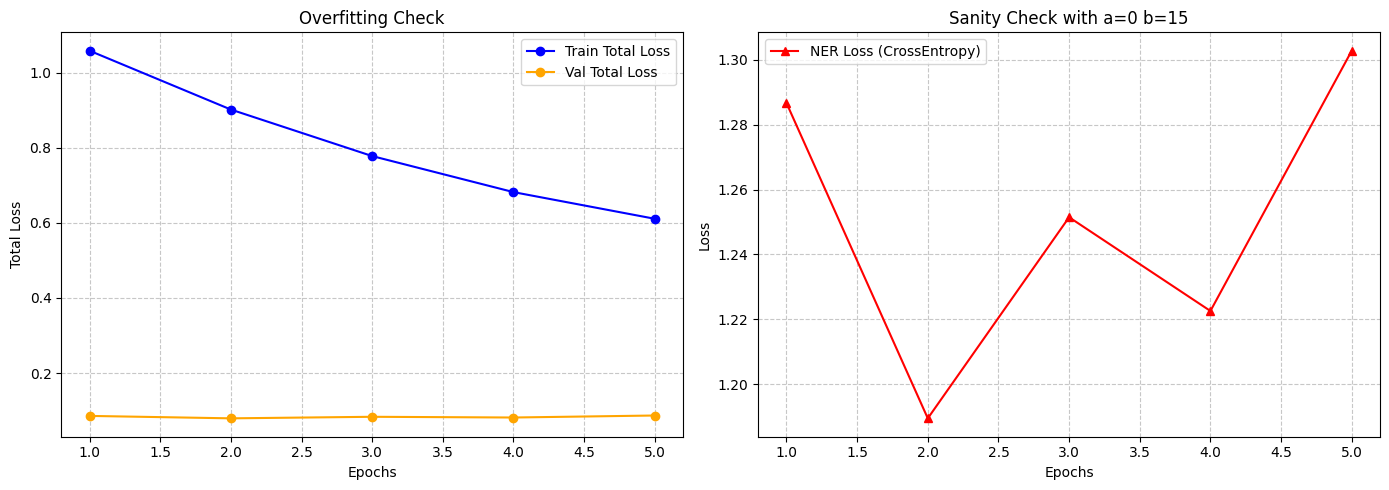

In [75]:
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(14, 5))

# --- Plot 1: Train vs Val ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, phase1_train_loss, label='Train Total Loss', marker='o', color='blue')
plt.plot(epochs_range, phase1_val_loss, label='Val Total Loss', marker='o', color='orange')
plt.title('Overfitting Check')
plt.xlabel('Epochs')
plt.ylabel('Total Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# --- Plot 2: Compare scale Classification vs NER ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range, phase1_history_val_loss_n, label='NER Loss (CrossEntropy)', marker='^', color='red')
plt.title(f"Sanity Check with a={alpha} b={beta}")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Phase 2 Training, Teacher Forcing

Here, we will use all documents. For the documents that contain ground truth mentions, we will use these reliable annotations and apply mention pooling, keeping only the tokens that carry meaningful information.

For the documents that do not contain mentions, we will rely on the NER head.

In [77]:
epochs_phase2 = 5
alpha = 1
beta = 15

# Lists for plotting
phase2_train_loss = []
phase2_val_loss = []
phase2_history_val_loss_c = []
phase2_history_val_loss_n = []

model.load_state_dict(torch.load('best_elcardio_model_phase1_maxprecision.pth'))

parameters_phase2 = []
bert_params_p2 = {'params': model.bert.parameters() , 'lr': 1e-5, 'weight_decay': 0.01}
class_head_params_p2 = {'params': model.classification_head.parameters() , 'lr': 1e-3, 'weight_decay': 0.05}
ner_head_params_p2 = {'params': model.ner_head.parameters() , 'lr': 1e-3, 'weight_decay': 0.1}

parameters_phase2.append(bert_params_p2)
parameters_phase2.append(class_head_params_p2)
parameters_phase2.append(ner_head_params_p2)

optimizer = AdamW(parameters_phase2)

best_val_loss = float('inf')

model.to(device)

print(f"Starting Phase1 on {device} for {epochs_phase2} epochs...\n")

# --- Main Epoch Loop ---
for epoch in range(epochs_phase2):
    print(f"======== Epoch {epoch + 1} / {epochs_phase2} ========")
    
    model.train() 
    total_train_loss = 0
    
    # Original train_loader
    train_progress = tqdm(train_loader, desc="Training (Rehearsal)")
    
    for batch in train_progress:
        b_input_ids = batch[0].to(device)      
        b_attn_mask = batch[1].to(device)      
        b_ner_labels = batch[2].to(device)     
        b_class_labels = batch[3].to(device)   
        
        # 2. Clear gradients
        optimizer.zero_grad()
        
        # 3. Forward pass
        logits_class, logits_ner = model(b_input_ids, b_attn_mask,ner_labels=b_ner_labels,use_teacher_forcing=True)
 
        # 4. Losses
        loss_c = alpha * focal_binary_cross_entropy(logits_class, b_class_labels)
        loss_n = ner_cross_entropy(logits_ner, b_ner_labels)
        
        total_loss = loss_c
        if not torch.isnan(loss_n):
            total_loss += beta * loss_n
        
        # 5. Backward pass
        total_loss.backward()
        
        # 6. Update weights
        optimizer.step()
        
        total_train_loss += total_loss.item()
        train_progress.set_postfix({'batch_loss': total_loss.item()})
        
    avg_train_loss = total_train_loss / len(train_loader)
    phase2_train_loss.append(avg_train_loss)
    
    # ==========================================
    # VALIDATION
    # ==========================================
    model.eval() 
    total_val_loss_n = 0
    valid_ner_batches = 0

    all_val_logits = []
    all_val_targets = []
    all_val_patient_ids = []

    val_progress = tqdm(val_loader, desc="Validation")
    
    with torch.no_grad():
        for batch in val_progress:
            b_input_ids = batch[0].to(device)
            b_attn_mask = batch[1].to(device)
            b_ner_labels = batch[2].to(device)
            b_class_labels = batch[3].to(device)
            b_patient_ids = batch[4]
            
            logits_class, logits_ner = model(b_input_ids, b_attn_mask)
            
            # NER loss calculate
            loss_n = ner_cross_entropy(logits_ner, b_ner_labels)
            if not torch.isnan(loss_n):
                total_val_loss_n += loss_n.item()
                valid_ner_batches += 1
            
            # Classification
            all_val_logits.append(logits_class.cpu())
            all_val_targets.append(b_class_labels.cpu())
            all_val_patient_ids.append(b_patient_ids.cpu())

    cat_logits = torch.cat(all_val_logits).numpy()
    cat_targets = torch.cat(all_val_targets).numpy()
    cat_ids = torch.cat(all_val_patient_ids).numpy()  

    df_logits = pd.DataFrame(cat_logits)
    df_logits['patient_id'] = cat_ids
    
    df_targets = pd.DataFrame(cat_targets)
    df_targets['patient_id'] = cat_ids

    doc_logits_df = df_logits.groupby('patient_id').max()
    doc_targets_df = df_targets.groupby('patient_id').max()

    doc_logits_tensor = torch.tensor(doc_logits_df.values).to(device)
    doc_targets_tensor = torch.tensor(doc_targets_df.values).to(device)

    doc_loss_c = focal_binary_cross_entropy(doc_logits_tensor, doc_targets_tensor)

    if valid_ner_batches > 0:
        avg_val_loss_n = total_val_loss_n / valid_ner_batches
    else:
        avg_val_loss_n = 0.0

    avg_val_loss = (alpha * doc_loss_c.item()) + (beta * avg_val_loss_n)

    phase2_val_loss.append(avg_val_loss)
    phase2_history_val_loss_c.append(alpha * doc_loss_c.item())
    phase2_history_val_loss_n.append(beta * avg_val_loss_n)
    
    print(f"\nAverage Training Loss: {avg_train_loss:.4f}")
    print(f"Average Validation Loss: {avg_val_loss:.4f}")
    print(f"Classification losses {phase2_history_val_loss_c}")
    print(f"NER losses {phase2_history_val_loss_n}")

    if avg_val_loss < best_val_loss:
        print(f"Validation loss improved from {best_val_loss:.4f} to {avg_val_loss:.4f}. Saving model...")
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'best_elcardio_model_phase2_maxprecision.pth')
    else:
        print(f"Validation loss did not improve.")
    print("-" * 50 + "\n")

print("Training Complete! The best model weights are saved in 'best_elcardio_model_phase2_maxprecision.pth'.")

Starting Phase1 on cuda for 5 epochs...

======== Epoch 1 / 5 ========


Validation: 100%|██████████| 13/13 [00:07<00:00,  1.82it/s]



Average Training Loss: 3.9745
Average Validation Loss: 3.9183
Classification losses [2.7470645904541016]
NER losses [1.1712262756191194]
Validation loss improved from inf to 3.9183. Saving model...
--------------------------------------------------

======== Epoch 2 / 5 ========


Validation: 100%|██████████| 13/13 [00:07<00:00,  1.83it/s]



Average Training Loss: 2.6644
Average Validation Loss: 3.7421
Classification losses [2.7470645904541016, 2.4713308811187744]
NER losses [1.1712262756191194, 1.2707551941275597]
Validation loss improved from 3.9183 to 3.7421. Saving model...
--------------------------------------------------

======== Epoch 3 / 5 ========


...


Average Training Loss: 2.1585
Average Validation Loss: 3.7298
Classification losses [2.7470645904541016, 2.4713308811187744, 2.50524640083313]
NER losses [1.1712262756191194, 1.2707551941275597, 1.224545524455607]
Validation loss improved from 3.7421 to 3.7298. Saving model...
--------------------------------------------------

======== Epoch 4 / 5 ========


Validation: 100%|██████████| 13/13 [00:07<00:00,  1.83it/s]



Average Training Loss: 1.8714
Average Validation Loss: 3.5510
Classification losses [2.7470645904541016, 2.4713308811187744, 2.50524640083313, 2.3633124828338623]
NER losses [1.1712262756191194, 1.2707551941275597, 1.224545524455607, 1.1876435671001673]
Validation loss improved from 3.7298 to 3.5510. Saving model...
--------------------------------------------------

======== Epoch 5 / 5 ========


Validation: 100%|██████████| 13/13 [00:07<00:00,  1.83it/s]


Average Training Loss: 1.5975
Average Validation Loss: 3.8491
Classification losses [2.7470645904541016, 2.4713308811187744, 2.50524640083313, 2.3633124828338623, 2.5062155723571777]
NER losses [1.1712262756191194, 1.2707551941275597, 1.224545524455607, 1.1876435671001673, 1.3429046049714088]
Validation loss did not improve.
--------------------------------------------------

Training Complete! The best model weights are saved in 'best_elcardio_model_phase2_maxprecision.pth'.


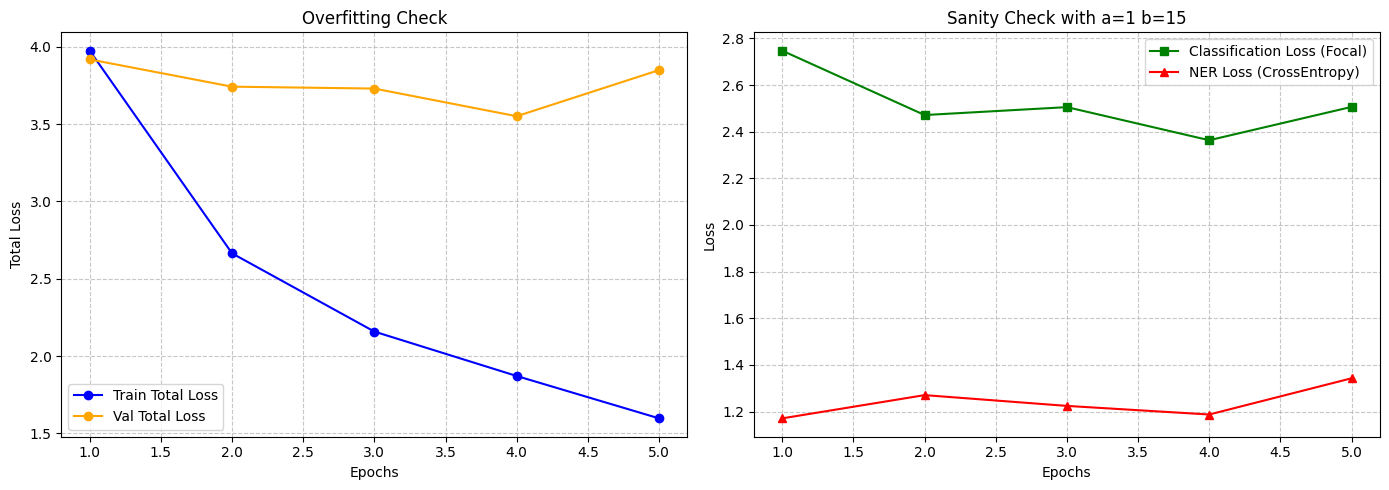

In [78]:
epochs_range = range(1, epochs_phase2 + 1)

plt.figure(figsize=(14, 5))

# --- Plot 1: Train vs Val ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, phase2_train_loss, label='Train Total Loss', marker='o', color='blue')
plt.plot(epochs_range, phase2_val_loss, label='Val Total Loss', marker='o', color='orange')
plt.title('Overfitting Check')
plt.xlabel('Epochs')
plt.ylabel('Total Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# --- Plot 2: Compare scale Classification vs NER ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range, phase2_history_val_loss_c, label='Classification Loss (Focal)', marker='s', color='green')
plt.plot(epochs_range, phase2_history_val_loss_n, label='NER Loss (CrossEntropy)', marker='^', color='red')
plt.title(f"Sanity Check with a={alpha} b={beta}")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Phase 3. All documents,no teacher forcing, fine tune

In [79]:
epochs_phase3 = 4
alpha = 1
beta = 10

# Lists for plotting
phase3_train_loss = []
phase3_val_loss = []
phase3_history_val_loss_c = []
phase3_history_val_loss_n = []

model.load_state_dict(torch.load('best_elcardio_model_phase2_maxprecision.pth'))

parameters_phase3 = []
bert_params_p3 = {'params': model.bert.parameters() , 'lr': 1e-6, 'weight_decay': 0.01}
class_head_params_p3 = {'params': model.classification_head.parameters() , 'lr': 1e-4, 'weight_decay': 0.05}
ner_head_params_p3 = {'params': model.ner_head.parameters() , 'lr': 1e-4, 'weight_decay': 0.1}

parameters_phase3.append(bert_params_p3)
parameters_phase3.append(class_head_params_p3)
parameters_phase3.append(ner_head_params_p3)

optimizer = AdamW(parameters_phase3)

best_val_loss = float('inf')

model.to(device)

print(f"Starting Phase 3 on {device} for {epochs_phase3} epochs...\n")

# --- Main Epoch Loop ---
for epoch in range(epochs_phase3):
    print(f"======== Epoch {epoch + 1} / {epochs_phase3} ========")
    
    model.train() 
    total_train_loss = 0
    
    # Original train_loader
    train_progress = tqdm(train_loader, desc="Training")
    
    for batch in train_progress:
        b_input_ids = batch[0].to(device)      
        b_attn_mask = batch[1].to(device)      
        b_ner_labels = batch[2].to(device)     
        b_class_labels = batch[3].to(device)   
        
        # 2. Clear gradients
        optimizer.zero_grad()
        
        # 3. Forward pass
        logits_class, logits_ner = model(b_input_ids, b_attn_mask,ner_labels=None,use_teacher_forcing=False)
 
        # 4. Losses
        loss_c = alpha * focal_binary_cross_entropy(logits_class, b_class_labels)
        loss_n = ner_cross_entropy(logits_ner, b_ner_labels)
        
        total_loss = loss_c
        if not torch.isnan(loss_n):
            total_loss += beta * loss_n
        
        # 5. Backward pass
        total_loss.backward()
        
        # 6. Update weights
        optimizer.step()
        
        total_train_loss += total_loss.item()
        train_progress.set_postfix({'batch_loss': total_loss.item()})
        
    avg_train_loss = total_train_loss / len(train_loader)
    phase3_train_loss.append(avg_train_loss)
    
    # ==========================================
    # VALIDATION
    # ==========================================
    model.eval() 
    total_val_loss_n = 0
    valid_ner_batches = 0

    all_val_logits = []
    all_val_targets = []
    all_val_patient_ids = []

    val_progress = tqdm(val_loader, desc="Validation")
    
    with torch.no_grad():
        for batch in val_progress:
            b_input_ids = batch[0].to(device)
            b_attn_mask = batch[1].to(device)
            b_ner_labels = batch[2].to(device)
            b_class_labels = batch[3].to(device)
            b_patient_ids = batch[4]
            
            logits_class, logits_ner = model(b_input_ids, b_attn_mask)
            
            # NER loss calculate
            loss_n = ner_cross_entropy(logits_ner, b_ner_labels)
            if not torch.isnan(loss_n):
                total_val_loss_n += loss_n.item()
                valid_ner_batches += 1
            
            # Classification
            all_val_logits.append(logits_class.cpu())
            all_val_targets.append(b_class_labels.cpu())
            all_val_patient_ids.append(b_patient_ids.cpu())

    cat_logits = torch.cat(all_val_logits).numpy()
    cat_targets = torch.cat(all_val_targets).numpy()
    cat_ids = torch.cat(all_val_patient_ids).numpy()  

    df_logits = pd.DataFrame(cat_logits)
    df_logits['patient_id'] = cat_ids
    
    df_targets = pd.DataFrame(cat_targets)
    df_targets['patient_id'] = cat_ids

    doc_logits_df = df_logits.groupby('patient_id').max()
    doc_targets_df = df_targets.groupby('patient_id').max()

    doc_logits_tensor = torch.tensor(doc_logits_df.values).to(device)
    doc_targets_tensor = torch.tensor(doc_targets_df.values).to(device)

    doc_loss_c = focal_binary_cross_entropy(doc_logits_tensor, doc_targets_tensor)

    if valid_ner_batches > 0:
        avg_val_loss_n = total_val_loss_n / valid_ner_batches
    else:
        avg_val_loss_n = 0.0

    avg_val_loss = (alpha * doc_loss_c.item()) + (beta * avg_val_loss_n)

    phase3_val_loss.append(avg_val_loss)
    phase3_history_val_loss_c.append(alpha * doc_loss_c.item())
    phase3_history_val_loss_n.append(beta * avg_val_loss_n)
    
    print(f"\nAverage Training Loss: {avg_train_loss:.4f}")
    print(f"Average Validation Loss: {avg_val_loss:.4f}")
    print(f"Classification losses {phase3_history_val_loss_c}")
    print(f"NER losses {phase3_history_val_loss_n}")

    if avg_val_loss < best_val_loss:
        print(f"Validation loss improved from {best_val_loss:.4f} to {avg_val_loss:.4f}. Saving model...")
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'best_elcardio_model_phase3_maxprecision.pth')
    else:
        print(f"Validation loss did not improve.")
    print("-" * 50 + "\n")

print("Training Complete! The best model weights are saved in 'best_elcardio_model_phase3_maxprecision.pth'.")

Starting Phase 3 on cuda for 4 epochs...

======== Epoch 1 / 4 ========


Validation: 100%|██████████| 13/13 [00:07<00:00,  1.83it/s]



Average Training Loss: 1.3339
Average Validation Loss: 3.0032
Classification losses [2.179793119430542]
NER losses [0.8234020695090294]
Validation loss improved from inf to 3.0032. Saving model...
--------------------------------------------------

======== Epoch 2 / 4 ========


Validation: 100%|██████████| 13/13 [00:07<00:00,  1.83it/s]



Average Training Loss: 1.2372
Average Validation Loss: 2.9941
Classification losses [2.179793119430542, 2.1771750450134277]
NER losses [0.8234020695090294, 0.8169178664684296]
Validation loss improved from 3.0032 to 2.9941. Saving model...
--------------------------------------------------

======== Epoch 3 / 4 ========


Validation: 100%|██████████| 13/13 [00:07<00:00,  1.83it/s]



Average Training Loss: 1.1917
Average Validation Loss: 2.9811
Classification losses [2.179793119430542, 2.1771750450134277, 2.1647350788116455]
NER losses [0.8234020695090294, 0.8169178664684296, 0.8164086379110813]
Validation loss improved from 2.9941 to 2.9811. Saving model...
--------------------------------------------------

======== Epoch 4 / 4 ========


Validation: 100%|██████████| 13/13 [00:07<00:00,  1.82it/s]


Average Training Loss: 1.1541
Average Validation Loss: 3.0047
Classification losses [2.179793119430542, 2.1771750450134277, 2.1647350788116455, 2.181663751602173]
NER losses [0.8234020695090294, 0.8169178664684296, 0.8164086379110813, 0.8230475429445505]
Validation loss did not improve.
--------------------------------------------------

Training Complete! The best model weights are saved in 'best_elcardio_model_phase3_maxprecision.pth'.


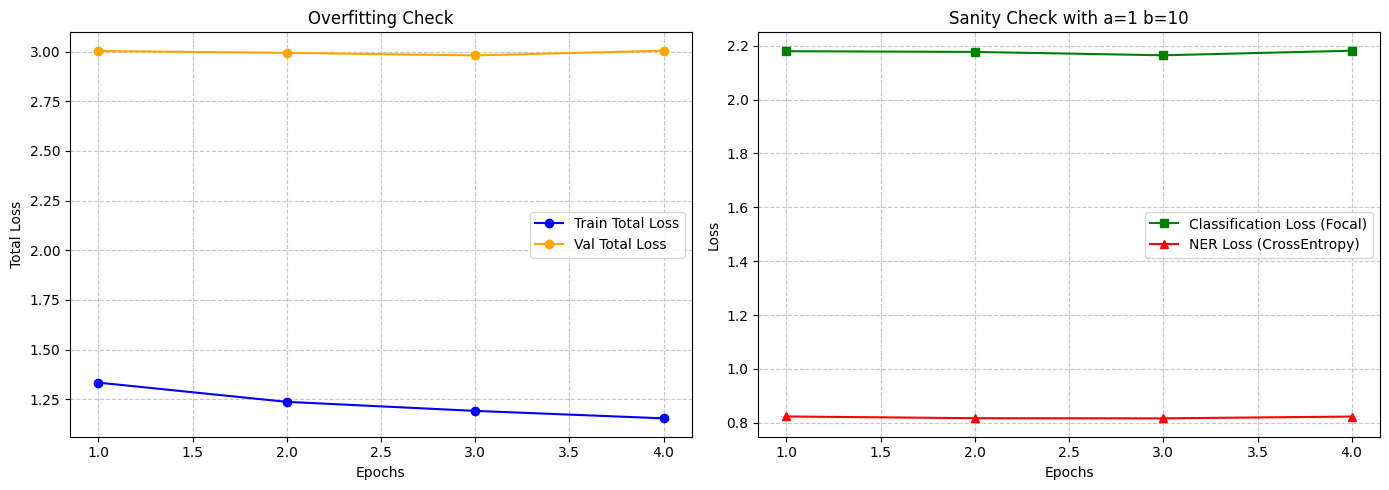

In [80]:
epochs_range = range(1, epochs_phase3 + 1)

plt.figure(figsize=(14, 5))

# --- Plot 1: Train vs Val ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, phase3_train_loss, label='Train Total Loss', marker='o', color='blue')
plt.plot(epochs_range, phase3_val_loss, label='Val Total Loss', marker='o', color='orange')
plt.title('Overfitting Check')
plt.xlabel('Epochs')
plt.ylabel('Total Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# --- Plot 2: Compare scale Classification vs NER ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range, phase3_history_val_loss_c, label='Classification Loss (Focal)', marker='s', color='green')
plt.plot(epochs_range, phase3_history_val_loss_n, label='NER Loss (CrossEntropy)', marker='^', color='red')
plt.title(f"Sanity Check with a={alpha} b={beta}")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Threshold Tuning

In [105]:
print("Extract predictions from Validation Set...")
model.load_state_dict(torch.load('best_elcardio_model_phase3_maxprecision.pth'))
model.eval()
val_probs_list = []
val_targets_list = []
val_patient_ids_list = []

with torch.no_grad():
    for batch in val_loader:
        b_input_ids = batch[0].to(device)
        b_attn_mask = batch[1].to(device)
        b_class_labels = batch[3].to(device)
        b_patient_ids = batch[4]

        logits_class, _ = model(b_input_ids, b_attn_mask, ner_labels=None, use_teacher_forcing=False)
        probs = torch.sigmoid(logits_class)

        val_probs_list.append(probs.cpu().numpy())
        val_targets_list.append(b_class_labels.cpu().numpy())
        val_patient_ids_list.append(b_patient_ids.numpy())

# Max Pooling (Validation)
df_val_probs = pd.DataFrame(np.vstack(val_probs_list))
df_val_probs['patient_id'] = np.concatenate(val_patient_ids_list)
doc_val_probs = df_val_probs.groupby('patient_id').max().values

df_val_targets = pd.DataFrame(np.vstack(val_targets_list))
df_val_targets['patient_id'] = np.concatenate(val_patient_ids_list)
doc_val_targets = df_val_targets.groupby('patient_id').max().values

Εξαγωγή προβλέψεων από το Validation Set...


In [106]:
TARGET_PRECISION = 0.90
num_classes = doc_val_targets.shape[1]

best_sniper_thresholds = np.full(num_classes, 0.5)
classes_hitting_target = 0

print(f"\n🔍 Searching Thresholds (Target Precision >= {TARGET_PRECISION}) on VALIDATION SET...")

thresholds_to_try = np.arange(0.05, 0.96, 0.01)

for i in range(num_classes):
    # validation real labels
    if np.sum(doc_val_targets[:, i]) == 0:
        continue
        
    best_th = 0.5
    max_recall_at_target_p = -1
    max_absolute_p = -1
    th_for_max_absolute_p = 0.5
    
    for th in thresholds_to_try:
        preds = (doc_val_probs[:, i] > th).astype(int)
        
        TP = np.sum((doc_val_targets[:, i] == 1) & (preds == 1))
        FP = np.sum((doc_val_targets[:, i] == 0) & (preds == 1))
        FN = np.sum((doc_val_targets[:, i] == 1) & (preds == 0))
        
        p = TP / (TP + FP) if (TP + FP) > 0 else 0.0
        r = TP / (TP + FN) if (TP + FN) > 0 else 0.0
        
        if p > max_absolute_p:
            max_absolute_p = p
            th_for_max_absolute_p = th
        
        if p >= TARGET_PRECISION:
            if r > max_recall_at_target_p:
                max_recall_at_target_p = r
                best_th = th
                
    if max_recall_at_target_p != -1:
        best_sniper_thresholds[i] = best_th
        classes_hitting_target += 1
    else:
        best_sniper_thresholds[i] = th_for_max_absolute_p if max_absolute_p > 0 else 0.95

print(f"{classes_hitting_target} from {num_classes} labels have 90% precision.")


🔍 Αναζήτηση 'Χειρουργικών' Thresholds (Target Precision >= 0.9) στο VALIDATION SET...
✅ Βρέθηκαν! 47 από τις 110 παθήσεις έπιασαν το 90% Precision στο Validation.


## Testing

In [107]:
class ElCardioModel_maxrecall(nn.Module):
    def __init__(self):
        super().__init__()

        # Greek Bert with no heads
        self.bert = AutoModel.from_pretrained("nlpaueb/bert-base-greek-uncased-v1")

        # Dropout for regularization
        self.dropout = nn.Dropout(p=0.1)

        # Classification Head
        self.classification_head = nn.Linear(768,110)

        # NER Head
        self.ner_head = nn.Linear(768,221)


    def forward(self, input_ids, attention_mask):
        
        bert_output = self.bert(input_ids,attention_mask)
        sequence_bert_output = bert_output.last_hidden_state 

        sequence_bert_output = self.dropout(sequence_bert_output)
        # classification head
        classification = self.classification_head(sequence_bert_output[:, 0, :])

        # NER head
        ner = self.ner_head(sequence_bert_output)

        return classification, ner

In [120]:
# --- 1. Load the Best Models ---
model.load_state_dict(torch.load('best_elcardio_model_phase3_maxprecision.pth'))
model.eval() 

model_max_recall = ElCardioModel_maxrecall().to(device)
model_max_recall.load_state_dict(torch.load('/kaggle/input/notebooks/dimitriospakakis/elcardio-max-recall/best_elcardio_model_final.pth'))
model_max_recall.eval()

# Load the precision Thresholds
try:
    best_sniper_thresholds = np.load('best_sniper_thresholds.npy')
    print("Precision Threhsolds Load.")
except FileNotFoundError:
    raise

SWEEPER_GLOBAL_THRESHOLD = 0.6


# Extract Probabilities from test
test_probs_sniper_list = []
test_probs_sweeper_list = []
test_targets_list = []
test_patient_ids_list = []

print("\nInference to test set from both models")
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing Ensemble"):
        b_input_ids = batch[0].to(device)
        b_attn_mask = batch[1].to(device)
        b_class_labels = batch[3].to(device)
        b_patient_ids = batch[4]

        logits_sniper, _ = model(b_input_ids, b_attn_mask, ner_labels=None, use_teacher_forcing=False)
        probs_sniper = torch.sigmoid(logits_sniper)

        logits_sweeper, _ = model_max_recall(b_input_ids, b_attn_mask)
        probs_sweeper = torch.sigmoid(logits_sweeper)

        test_probs_sniper_list.append(probs_sniper.cpu().numpy())
        test_probs_sweeper_list.append(probs_sweeper.cpu().numpy())
        test_targets_list.append(b_class_labels.cpu().numpy())
        test_patient_ids_list.append(b_patient_ids.numpy())

# --- Max Pooling per document (Patient ID) ---
patient_ids_array = np.concatenate(test_patient_ids_list)
doc_targets = pd.DataFrame(np.vstack(test_targets_list)).assign(patient_id=patient_ids_array).groupby('patient_id').max().values

doc_probs_sniper = pd.DataFrame(np.vstack(test_probs_sniper_list)).assign(patient_id=patient_ids_array).groupby('patient_id').max().values
doc_probs_sweeper = pd.DataFrame(np.vstack(test_probs_sweeper_list)).assign(patient_id=patient_ids_array).groupby('patient_id').max().values


# Convert probabilities to 0 or 1 respect ot the thresholds
print("\nApply Thresholds...")

preds_sniper = (doc_probs_sniper > best_sniper_thresholds).astype(int)

preds_sweeper = (doc_probs_sweeper > SWEEPER_GLOBAL_THRESHOLD).astype(int)


# CLASS-BASED ROUTING / THE MASK
print("\nRouting...")

final_ensemble_preds = np.zeros_like(preds_sniper)

# labels that have more than 80% precision
sniper_classes_mask = (best_sniper_thresholds < 0.8)

num_sniper_classes = np.sum(sniper_classes_mask)
num_sweeper_classes = len(sniper_classes_mask) - num_sniper_classes

print(f"Max Precision take on {num_sniper_classes} labels.")
print(f"Max Recall take on {num_sweeper_classes} labels.")

# Rule 1: On the precision labels use the max precision model predictions
final_ensemble_preds[:, sniper_classes_mask] = preds_sniper[:, sniper_classes_mask]

# Rule 2: On the recall labels use the max recall model predictions
final_ensemble_preds[:, ~sniper_classes_mask] = preds_sweeper[:, ~sniper_classes_mask]



micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
    doc_targets, final_ensemble_preds, average='micro', zero_division=0
)
print(f"MICRO - Precision: {micro_p:.4f} | Recall: {micro_r:.4f} | F1-Score: {micro_f1:.4f}")

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    doc_targets, final_ensemble_preds, average='macro', zero_division=0
)
print(f"MACRO - Precision: {macro_p:.4f} | Recall: {macro_r:.4f} | F1-Score: {macro_f1:.4f}")

total_predictions = np.sum(final_ensemble_preds)
mean_labels = total_predictions / len(doc_targets)
print(f"\nTotal predictions: {total_predictions} ({mean_labels:.2f} per document)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: nlpaueb/bert-base-greek-uncased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Φορτώθηκαν τα Χειρουργικά thresholds του Σκοπευτή.
✅ Η Σκούπα ρυθμίστηκε με Global Threshold: 0.6

[1/3] Τρέχουμε το Test Set και στα δύο μοντέλα...


Testing Ensemble: 100%|██████████| 13/13 [00:11<00:00,  1.10it/s]



[2/3] Εφαρμογή των Thresholds...

[3/3] Ένωση των προβλέψεων (Routing)...
👨‍⚕️ Ο Σκοπευτής (Max Precision) αναλαμβάνει 100 παθήσεις.
🩺 Η Σκούπα (Max Recall @ 0.3) αναλαμβάνει τις υπόλοιπες 10 παθήσεις.

🏆 ΤΕΛΙΚΑ ΣΚΟΡ ΣΥΣΤΗΜΑΤΟΣ (ENSEMBLE) ΣΤΟ TEST SET
MICRO - Precision: 0.7252 | Recall: 0.8173 | F1-Score: 0.7685
MACRO - Precision: 0.4755 | Recall: 0.5060 | F1-Score: 0.4370

Συνολικές Προβλέψεις: 808 (Μέσος όρος 6.31 ανά έγγραφο)
